In [76]:
import numpy as np
import pandas as pd
import os
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [77]:
def load_csv(file_path):
    """Loads a CSV file into a DataFrame"""
    try:
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Error: File '{file_path}' not found!")

        df = pd.read_csv(file_path)

        print(f"✅ CSV file! Shape: {df.shape}")

        return df
    except FileNotFoundError as fnf_error:
        print(fnf_error)
    except pd.errors.EmptyDataError:
        print("Error: The CSV file is empty!")
    except pd.errors.ParserError:
        print("Error: CSV parsing issue. Check the file format.")
    except Exception as e:
        print(f"Unexpected error: {e}")

    return None  

In [78]:
df = pd.read_csv('/kaggle/input/parkinsons-disease-dataset-analysis/parkinsons_disease_data.csv')

# Quick peek on data

In [79]:
df.head(3)

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis,DoctorInCharge
0,3058,85,0,3,1,19.619878,0,5.108241,1.380660,3.893969,...,1.572427,1,0,0,0,0,0,0,0,DrXXXConfid
1,3059,75,0,0,2,16.247339,1,6.027648,8.409804,8.513428,...,4.787551,0,1,0,1,0,1,0,1,DrXXXConfid
2,3060,70,1,0,0,15.368239,0,2.242135,0.213275,6.498805,...,2.130686,1,0,0,0,1,0,1,1,DrXXXConfid


In [80]:

df.shape

(2105, 35)

In [81]:
# Correct way - pass column names as a list
df = df.drop(["DoctorInCharge", "PatientID", "EducationLevel"], axis=1)

In [82]:
df.shape

(2105, 32)

In [83]:

def get_basic_info(df):
    """Get basic information about the dataset"""
    print(f"🔹 Number of Rows: {df.shape[0]}")
    print(f"🔹 Number of Columns: {df.shape[1]}")
    print(f"🔹 Columns: {df.columns.tolist()}")
    print(f"🔹 Column Data Types: {df.dtypes}")
    print(f"🔹 Missing Values: {df.isnull().sum().sum()}")
    print(f"🔹 Missing Values (Per Column) : {df.isnull().sum()}")
    print(f"🔹 Missing Values (Per Column Percentage) : {(df.isnull().mean() * 100)}")
    print(f"🔹 Unique Values: {df.nunique()}")

In [84]:
get_basic_info(df)

🔹 Number of Rows: 2105
🔹 Number of Columns: 32
🔹 Columns: ['Age', 'Gender', 'Ethnicity', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryParkinsons', 'TraumaticBrainInjury', 'Hypertension', 'Diabetes', 'Depression', 'Stroke', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'UPDRS', 'MoCA', 'FunctionalAssessment', 'Tremor', 'Rigidity', 'Bradykinesia', 'PosturalInstability', 'SpeechProblems', 'SleepDisorders', 'Constipation', 'Diagnosis']
🔹 Column Data Types: Age                           int64
Gender                        int64
Ethnicity                     int64
BMI                         float64
Smoking                       int64
AlcoholConsumption          float64
PhysicalActivity            float64
DietQuality                 float64
SleepQuality                float64
FamilyHistoryParkinsons       int64
TraumaticBrainInjury          int64
Hypertension        

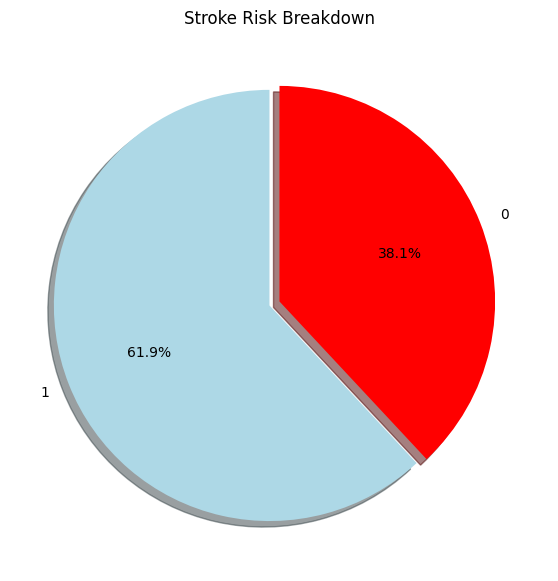

In [85]:
labels = df['Diagnosis'].value_counts(sort=True).index
sizes = df['Diagnosis'].value_counts(sort=True)

colors = ["lightblue", "red"]
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes[:2], explode=explode, labels=labels[:2], colors=colors, autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Stroke Risk Breakdown')
plt.show()

# Preprocessing Steps

In [86]:
# Check for class imbalance
df['Diagnosis'].value_counts()/len(df)

Diagnosis
1    0.619477
0    0.380523
Name: count, dtype: float64

In [87]:
# Check for duplicates  --> ~0.015%
print("Duplicates:", df.duplicated().sum()/len(df))
df.drop_duplicates(inplace=True)

Duplicates: 0.0


# 3. Handling Missing Values

In [88]:
# Missing values  --> no missing values
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 Age                         0
Gender                      0
Ethnicity                   0
BMI                         0
Smoking                     0
AlcoholConsumption          0
PhysicalActivity            0
DietQuality                 0
SleepQuality                0
FamilyHistoryParkinsons     0
TraumaticBrainInjury        0
Hypertension                0
Diabetes                    0
Depression                  0
Stroke                      0
SystolicBP                  0
DiastolicBP                 0
CholesterolTotal            0
CholesterolLDL              0
CholesterolHDL              0
CholesterolTriglycerides    0
UPDRS                       0
MoCA                        0
FunctionalAssessment        0
Tremor                      0
Rigidity                    0
Bradykinesia                0
PosturalInstability         0
SpeechProblems              0
SleepDisorders              0
Constipation                0
Diagnosis                   0
dtype: int64


In [89]:
def plot_missing_heatmap(df):
    """Plot a heatmap to visualize missing values in the dataset."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(df.isnull(), cmap="viridis", cbar=False, yticklabels=False)
    plt.title("Missing Data Heatmap")
    plt.show()

In [90]:
def plot_missing_bar(df):
    """Plot a bar chart showing the count of missing values per column."""
    missing_values = df.isnull().sum()
    missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

    if missing_values.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_values.index, y=missing_values.values, palette="magma")
    plt.xticks(rotation=90)
    plt.title("Missing Values Count per Column")
    plt.ylabel("Count")
    plt.show()

In [150]:
def plot_missing_pie(df):
    """Plot a pie chart showing the percentage of missing values per column."""
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if missing_percent.empty:
        print("✅ No missing values to plot.")
        return

    plt.figure(figsize=(8, 8))
    plt.pie(missing_percent, labels=missing_percent.index, autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title("Percentage of Missing Values per Column")
    plt.show()

In [151]:
plot_missing_heatmap(df)

✅ No missing values to plot.


In [152]:
plot_missing_bar(df)

✅ No missing values to plot.


In [153]:
plot_missing_pie(df)

✅ No missing values to plot.


In [154]:
df.head(3)

,Age,Gender,Ethnicity,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,...,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis
0,85,0,3,19.619878,0,5.108241,1.380660,3.893969,9.283194,0,...,29.181289,1.572427,1,0,0,0,0,0,0,0
1,75,0,0,16.247339,1,6.027648,8.409804,8.513428,5.602470,0,...,12.332639,4.787551,0,1,0,1,0,1,0,1
2,70,1,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,0,...,29.927783,2.130686,1,0,0,0,1,0,1,1


In [155]:
# plt.figure(figsize=(10,6))
# sns.pairplot(df,hue='Diagnosis',palette='mako')

# Dealing with all the numerical features(nulls/scailing)

In [156]:
numerical = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical

['Age',
 'Gender',
 'Ethnicity',
 'BMI',
 'Smoking',
 'AlcoholConsumption',
 'PhysicalActivity',
 'DietQuality',
 'SleepQuality',
 'FamilyHistoryParkinsons',
 'TraumaticBrainInjury',
 'Hypertension',
 'Diabetes',
 'Depression',
 'Stroke',
 'SystolicBP',
 'DiastolicBP',
 'CholesterolTotal',
 'CholesterolLDL',
 'CholesterolHDL',
 'CholesterolTriglycerides',
 'UPDRS',
 'MoCA',
 'FunctionalAssessment',
 'Tremor',
 'Rigidity',
 'Bradykinesia',
 'PosturalInstability',
 'SpeechProblems',
 'SleepDisorders',
 'Constipation',
 'Diagnosis']

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='Age', ylabel='Count'>

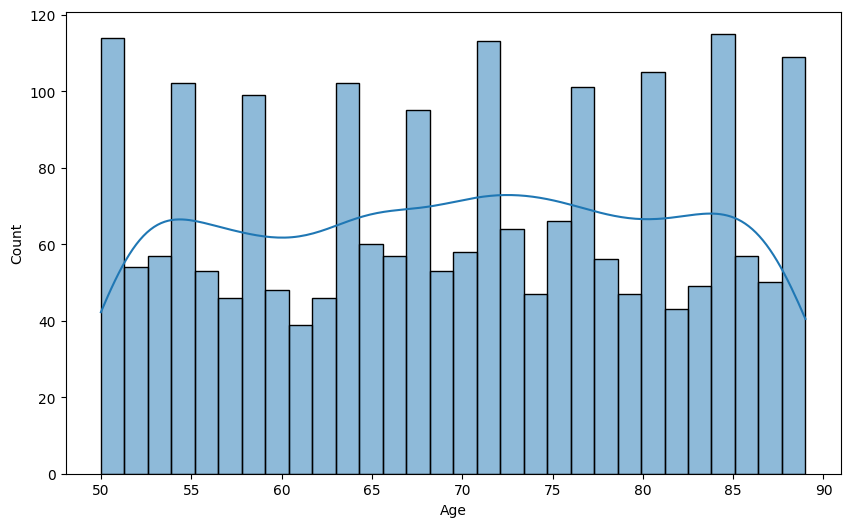

In [157]:
plt.figure(figsize=(10,6))
sns.histplot(df.Age,kde=True,bins=30)

# *Dealing with all the categorical features(nulls (if exists)/encoding)*

In [158]:
# categories = df.select_dtypes(include=['object']).columns.tolist()
# categories

In [159]:
df.Gender.value_counts()

Gender
0    1068
1    1037
Name: count, dtype: int64

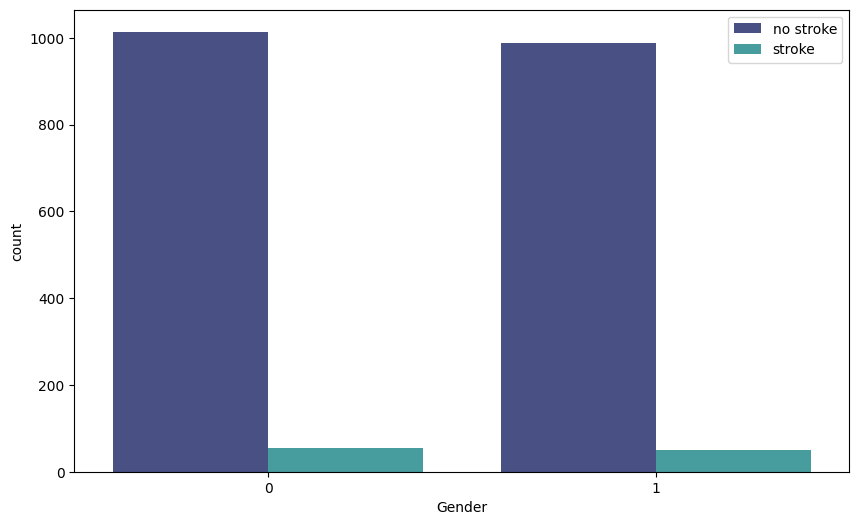

In [160]:
plt.figure(figsize=(10,6))
sns.countplot(x="Gender", data=df, palette='mako',hue='Stroke')
plt.legend(['no stroke','stroke'])

In [161]:
df.head()

,Age,Gender,Ethnicity,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,...,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis
0,85,0,3,19.619878,0,5.108241,1.380660,3.893969,9.283194,0,...,29.181289,1.572427,1,0,0,0,0,0,0,0
1,75,0,0,16.247339,1,6.027648,8.409804,8.513428,5.602470,0,...,12.332639,4.787551,0,1,0,1,0,1,0,1
2,70,1,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,0,...,29.927783,2.130686,1,0,0,0,1,0,1,1
3,52,0,0,15.454557,0,5.997788,1.375045,6.715033,4.196189,0,...,21.304268,3.391288,1,1,1,0,0,0,1,1
4,87,0,0,18.616042,0,9.775243,1.188607,4.657572,9.363925,0,...,8.336364,3.200969,0,0,0,1,0,1,0,0


In [162]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean': 
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")
            
    return df

In [163]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)  
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")
            
    return df

In [164]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value) 
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")
                
    return df

In [165]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """
    
    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df
    
    return df_imputed

In [166]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [167]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []
    
    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']: 
            if df[col].nunique() == 2:  
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':  
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [168]:
# df.head(10)

In [169]:
classify_columns(df)

{'binary': ['Gender',
  'Smoking',
  'FamilyHistoryParkinsons',
  'TraumaticBrainInjury',
  'Hypertension',
  'Diabetes',
  'Depression',
  'Stroke',
  'Tremor',
  'Rigidity',
  'Bradykinesia',
  'PosturalInstability',
  'SpeechProblems',
  'SleepDisorders',
  'Constipation',
  'Diagnosis'],
 'numerical': ['Age',
  'Ethnicity',
  'BMI',
  'AlcoholConsumption',
  'PhysicalActivity',
  'DietQuality',
  'SleepQuality',
  'SystolicBP',
  'DiastolicBP',
  'CholesterolTotal',
  'CholesterolLDL',
  'CholesterolHDL',
  'CholesterolTriglycerides',
  'UPDRS',
  'MoCA',
  'FunctionalAssessment'],
 'categorical': []}

In [170]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()
    
    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold: 
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")
    
    return filtered_classification

In [171]:
column_classification = {
    'binary': ['Gender',
  'Smoking',
  'FamilyHistoryParkinsons',
  'TraumaticBrainInjury',
  'Hypertension',
  'Diabetes',
  'Depression',
  'Stroke',
  'Tremor',
  'Rigidity',
  'Bradykinesia',
  'PosturalInstability',
  'SpeechProblems',
  'SleepDisorders',
  'Constipation',
  'Diagnosis'],
 'numerical': ['Age',
  'Ethnicity',
  'BMI',
  'AlcoholConsumption',
  'PhysicalActivity',
  'DietQuality',
  'SleepQuality',
  'SystolicBP',
  'DiastolicBP',
  'CholesterolTotal',
  'CholesterolLDL',
  'CholesterolHDL',
  'CholesterolTriglycerides',
  'UPDRS',
  'MoCA',
  'FunctionalAssessment'],
 'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['Gender', 'Smoking', 'FamilyHistoryParkinsons', 'TraumaticBrainInjury', 'Hypertension', 'Diabetes', 'Depression', 'Stroke', 'Tremor', 'Rigidity', 'Bradykinesia', 'PosturalInstability', 'SpeechProblems', 'SleepDisorders', 'Constipation', 'Diagnosis'], 'numerical': ['Age', 'Ethnicity', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'UPDRS', 'MoCA', 'FunctionalAssessment'], 'categorical': []}


In [ ]:
# df.head()
# df.isnull().sum()


In [172]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'Gender' with mode: 0
🔹 Imputed missing values in binary column 'Smoking' with mode: 0
🔹 Imputed missing values in binary column 'FamilyHistoryParkinsons' with mode: 0
🔹 Imputed missing values in binary column 'TraumaticBrainInjury' with mode: 0
🔹 Imputed missing values in binary column 'Hypertension' with mode: 0
🔹 Imputed missing values in binary column 'Diabetes' with mode: 0
🔹 Imputed missing values in binary column 'Depression' with mode: 0
🔹 Imputed missing values in binary column 'Stroke' with mode: 0
🔹 Imputed missing values in binary column 'Tremor' with mode: 0
🔹 Imputed missing values in binary column 'Rigidity' with mode: 0
🔹 Imputed missing values in binary column 'Bradykinesia' with mode: 0
🔹 Imputed missing values in binary column 'PosturalInstability' with mode: 0
🔹 Imputed missing values in binary column 'SpeechProblems' with mode: 0
🔹 Imputed missing values in binary column 'SleepDisorders' with mode: 0
🔹 Imputed missing value

,Age,Gender,Ethnicity,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,...,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis
0,85,0,3,19.619878,0,5.108241,1.380660,3.893969,9.283194,0,...,29.181289,1.572427,1,0,0,0,0,0,0,0
1,75,0,0,16.247339,1,6.027648,8.409804,8.513428,5.602470,0,...,12.332639,4.787551,0,1,0,1,0,1,0,1
2,70,1,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,0,...,29.927783,2.130686,1,0,0,0,1,0,1,1
3,52,0,0,15.454557,0,5.997788,1.375045,6.715033,4.196189,0,...,21.304268,3.391288,1,1,1,0,0,0,1,1
4,87,0,0,18.616042,0,9.775243,1.188607,4.657572,9.363925,0,...,8.336364,3.200969,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2100,87,1,0,38.483841,0,12.674393,5.325900,5.947278,6.296231,0,...,28.634010,8.076254,1,0,0,0,1,1,0,0
2101,67,0,0,33.694396,1,0.977018,0.108599,4.825187,6.342325,1,...,13.106537,1.665751,0,0,0,1,0,1,1,1
2102,65,0,0,22.829631,0,6.152286,5.775103,0.334244,9.740019,1,...,26.527734,4.785614,0,0,0,0,1,1,0,1
2103,61,1,0,16.871030,1,0.292094,2.280475,9.598513,8.289390,0,...,19.873404,8.378979,1,0,1,0,0,1,1,1


In [173]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'Age' with most frequent: 84
🔹 Imputed missing values in numerical column 'Ethnicity' with most frequent: 0
🔹 Imputed missing values in numerical column 'BMI' with most frequent: 19.619877964608285
🔹 Imputed missing values in numerical column 'AlcoholConsumption' with most frequent: 5.108240606772179
🔹 Imputed missing values in numerical column 'PhysicalActivity' with most frequent: 1.3806599170830036
🔹 Imputed missing values in numerical column 'DietQuality' with most frequent: 3.893969135156027
🔹 Imputed missing values in numerical column 'SleepQuality' with most frequent: 9.283194447541694
🔹 Imputed missing values in numerical column 'SystolicBP' with most frequent: 94
🔹 Imputed missing values in numerical column 'DiastolicBP' with most frequent: 96
🔹 Imputed missing values in numerical column 'CholesterolTotal' with most frequent: 222.8422778232232
🔹 Imputed missing values in numerical column 'CholesterolLDL' with most frequent: 148.1256

,Age,Gender,Ethnicity,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,...,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation,Diagnosis
0,85,0,3,19.619878,0,5.108241,1.380660,3.893969,9.283194,0,...,29.181289,1.572427,1,0,0,0,0,0,0,0
1,75,0,0,16.247339,1,6.027648,8.409804,8.513428,5.602470,0,...,12.332639,4.787551,0,1,0,1,0,1,0,1
2,70,1,0,15.368239,0,2.242135,0.213275,6.498805,9.929824,0,...,29.927783,2.130686,1,0,0,0,1,0,1,1
3,52,0,0,15.454557,0,5.997788,1.375045,6.715033,4.196189,0,...,21.304268,3.391288,1,1,1,0,0,0,1,1
4,87,0,0,18.616042,0,9.775243,1.188607,4.657572,9.363925,0,...,8.336364,3.200969,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2100,87,1,0,38.483841,0,12.674393,5.325900,5.947278,6.296231,0,...,28.634010,8.076254,1,0,0,0,1,1,0,0
2101,67,0,0,33.694396,1,0.977018,0.108599,4.825187,6.342325,1,...,13.106537,1.665751,0,0,0,1,0,1,1,1
2102,65,0,0,22.829631,0,6.152286,5.775103,0.334244,9.740019,1,...,26.527734,4.785614,0,0,0,0,1,1,0,1
2103,61,1,0,16.871030,1,0.292094,2.280475,9.598513,8.289390,0,...,19.873404,8.378979,1,0,1,0,0,1,1,1


<ipython-input-174-2ff6c6e5b347>:5: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df.hist(ax = ax)


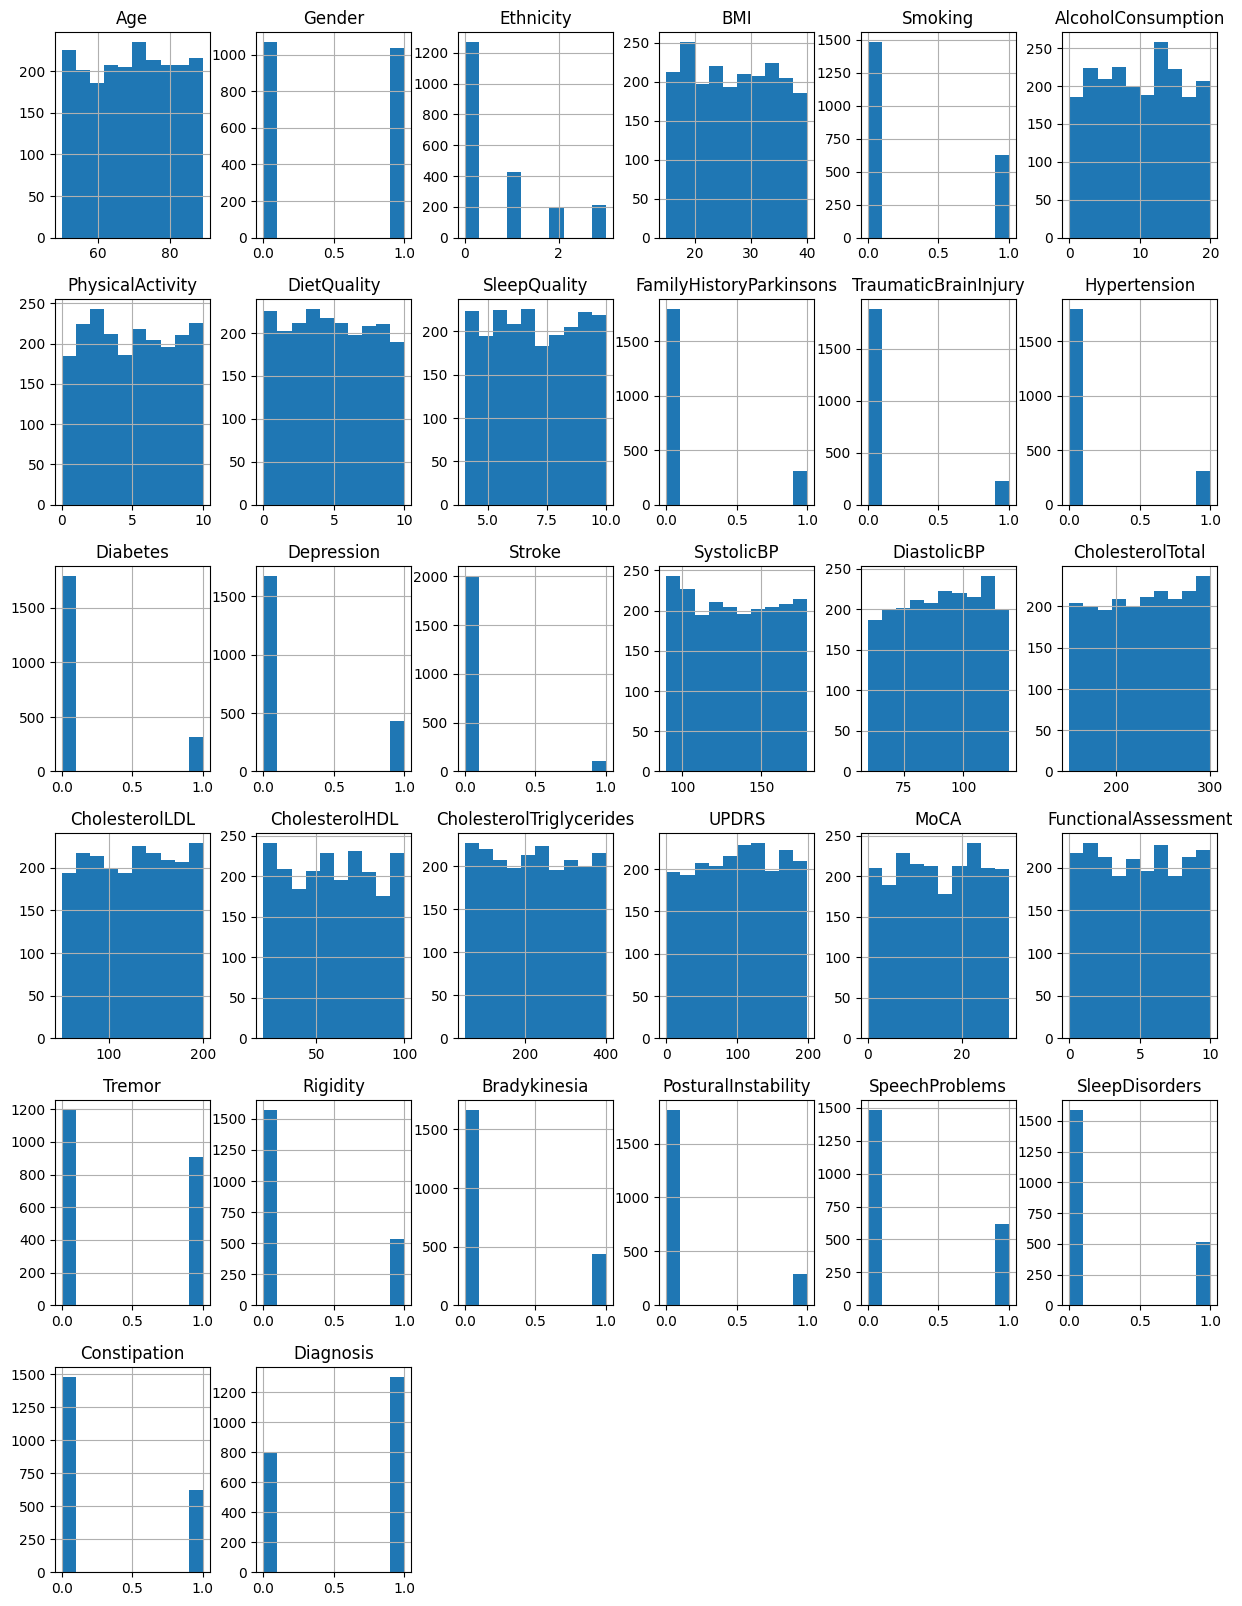

In [174]:
# Plot Histogram to See the Distribution of the Data

fig = plt.figure(figsize = (15,20))
ax = fig.gca()
df.hist(ax = ax)
plt.show()

Only stroke Partipants¶

<ipython-input-175-2cc65425bbe6>:6: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  dataset_copy.hist(ax = ax)


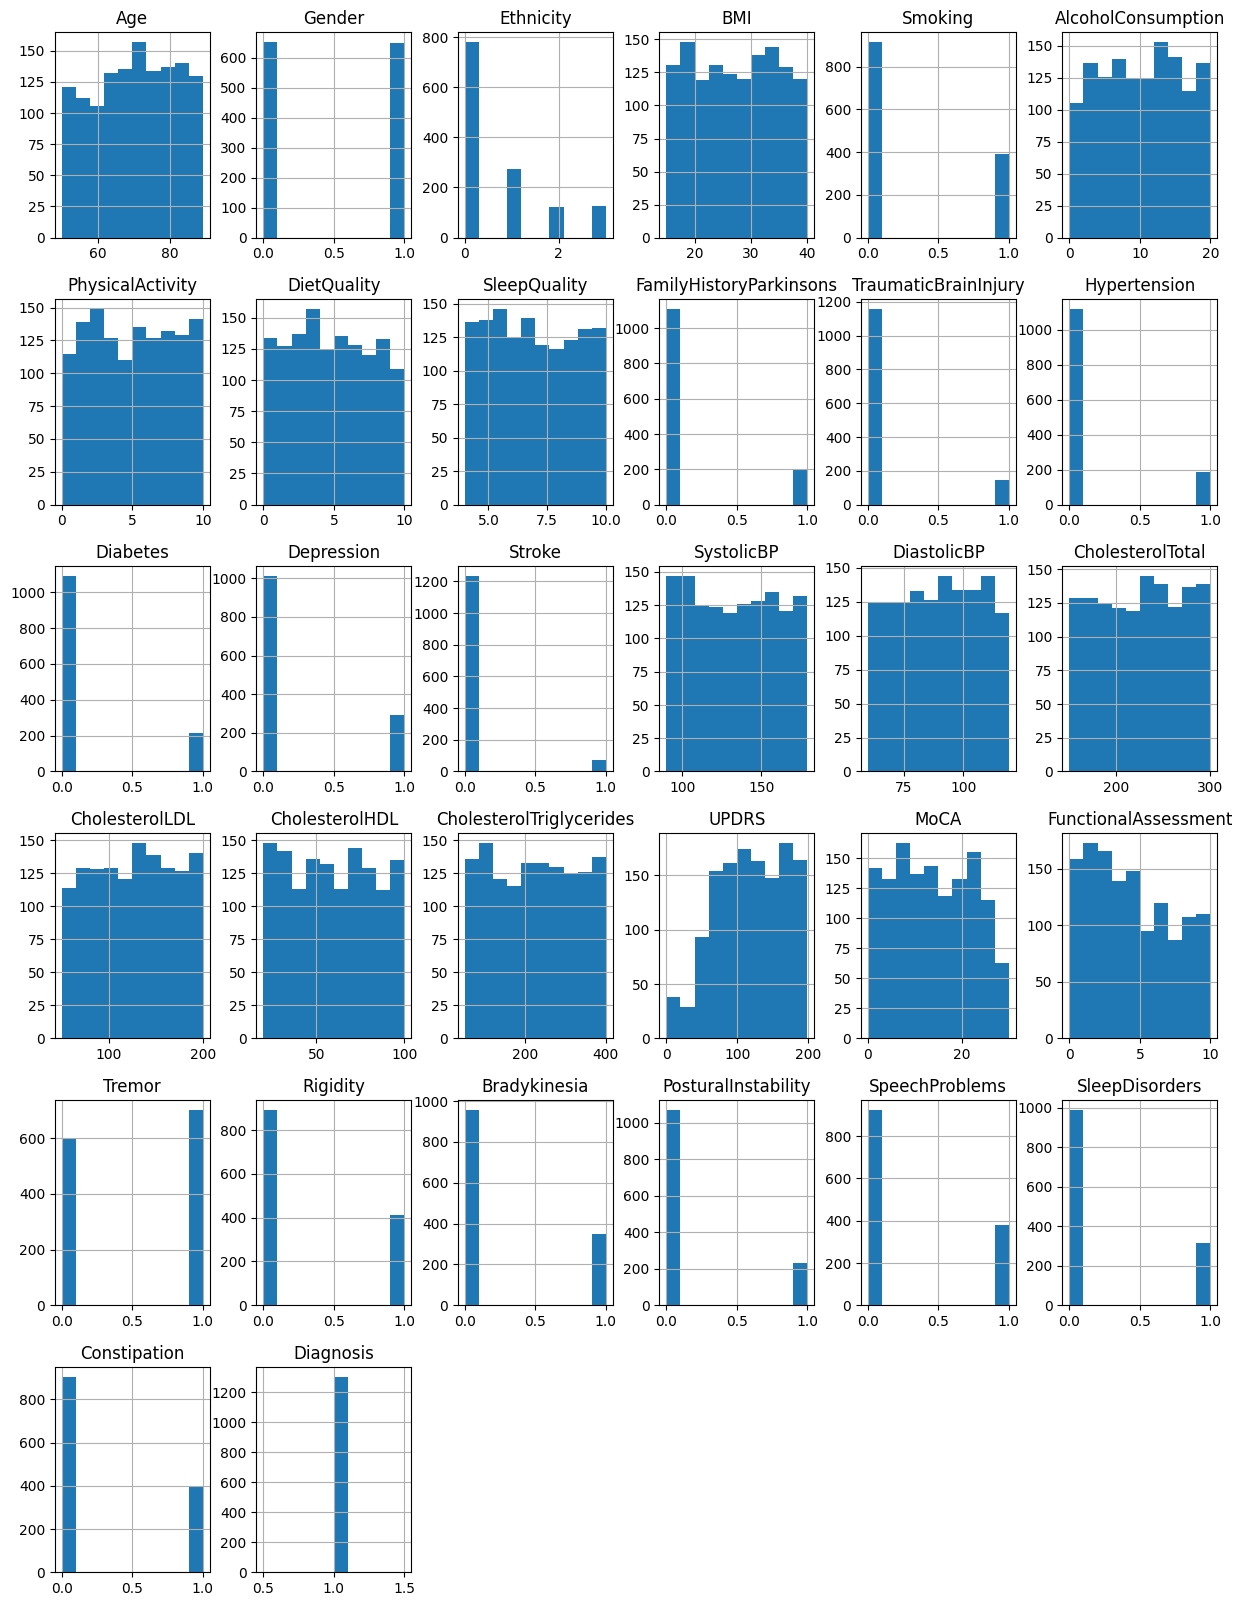

In [175]:
# Plot Histogram to See the Distribution of the Data for Heart Disease Cases
dataset_copy=df[df['Diagnosis']==1]
columns=df.columns[:21]
fig = plt.figure(figsize = (15,20))
ax = fig.gca()
dataset_copy.hist(ax = ax)
plt.show()

histogram

In [176]:
def plot_binary_distribution(df, binary_cols):
    """Plot count plots for binary features to visualize the distribution of 0s and 1s."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='Set2', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    # Hide any extra subplots
    for i in range(num_plots, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


boxplot

In [177]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distribution."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for i in range(num_plots, len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()


plot_kde

In [178]:
def plot_kde(df, numerical_cols):
    """Plot KDE (Kernel Density Estimate) for numerical features to visualize smooth distributions."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
        axes[i].set_title(f"KDE of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Density")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

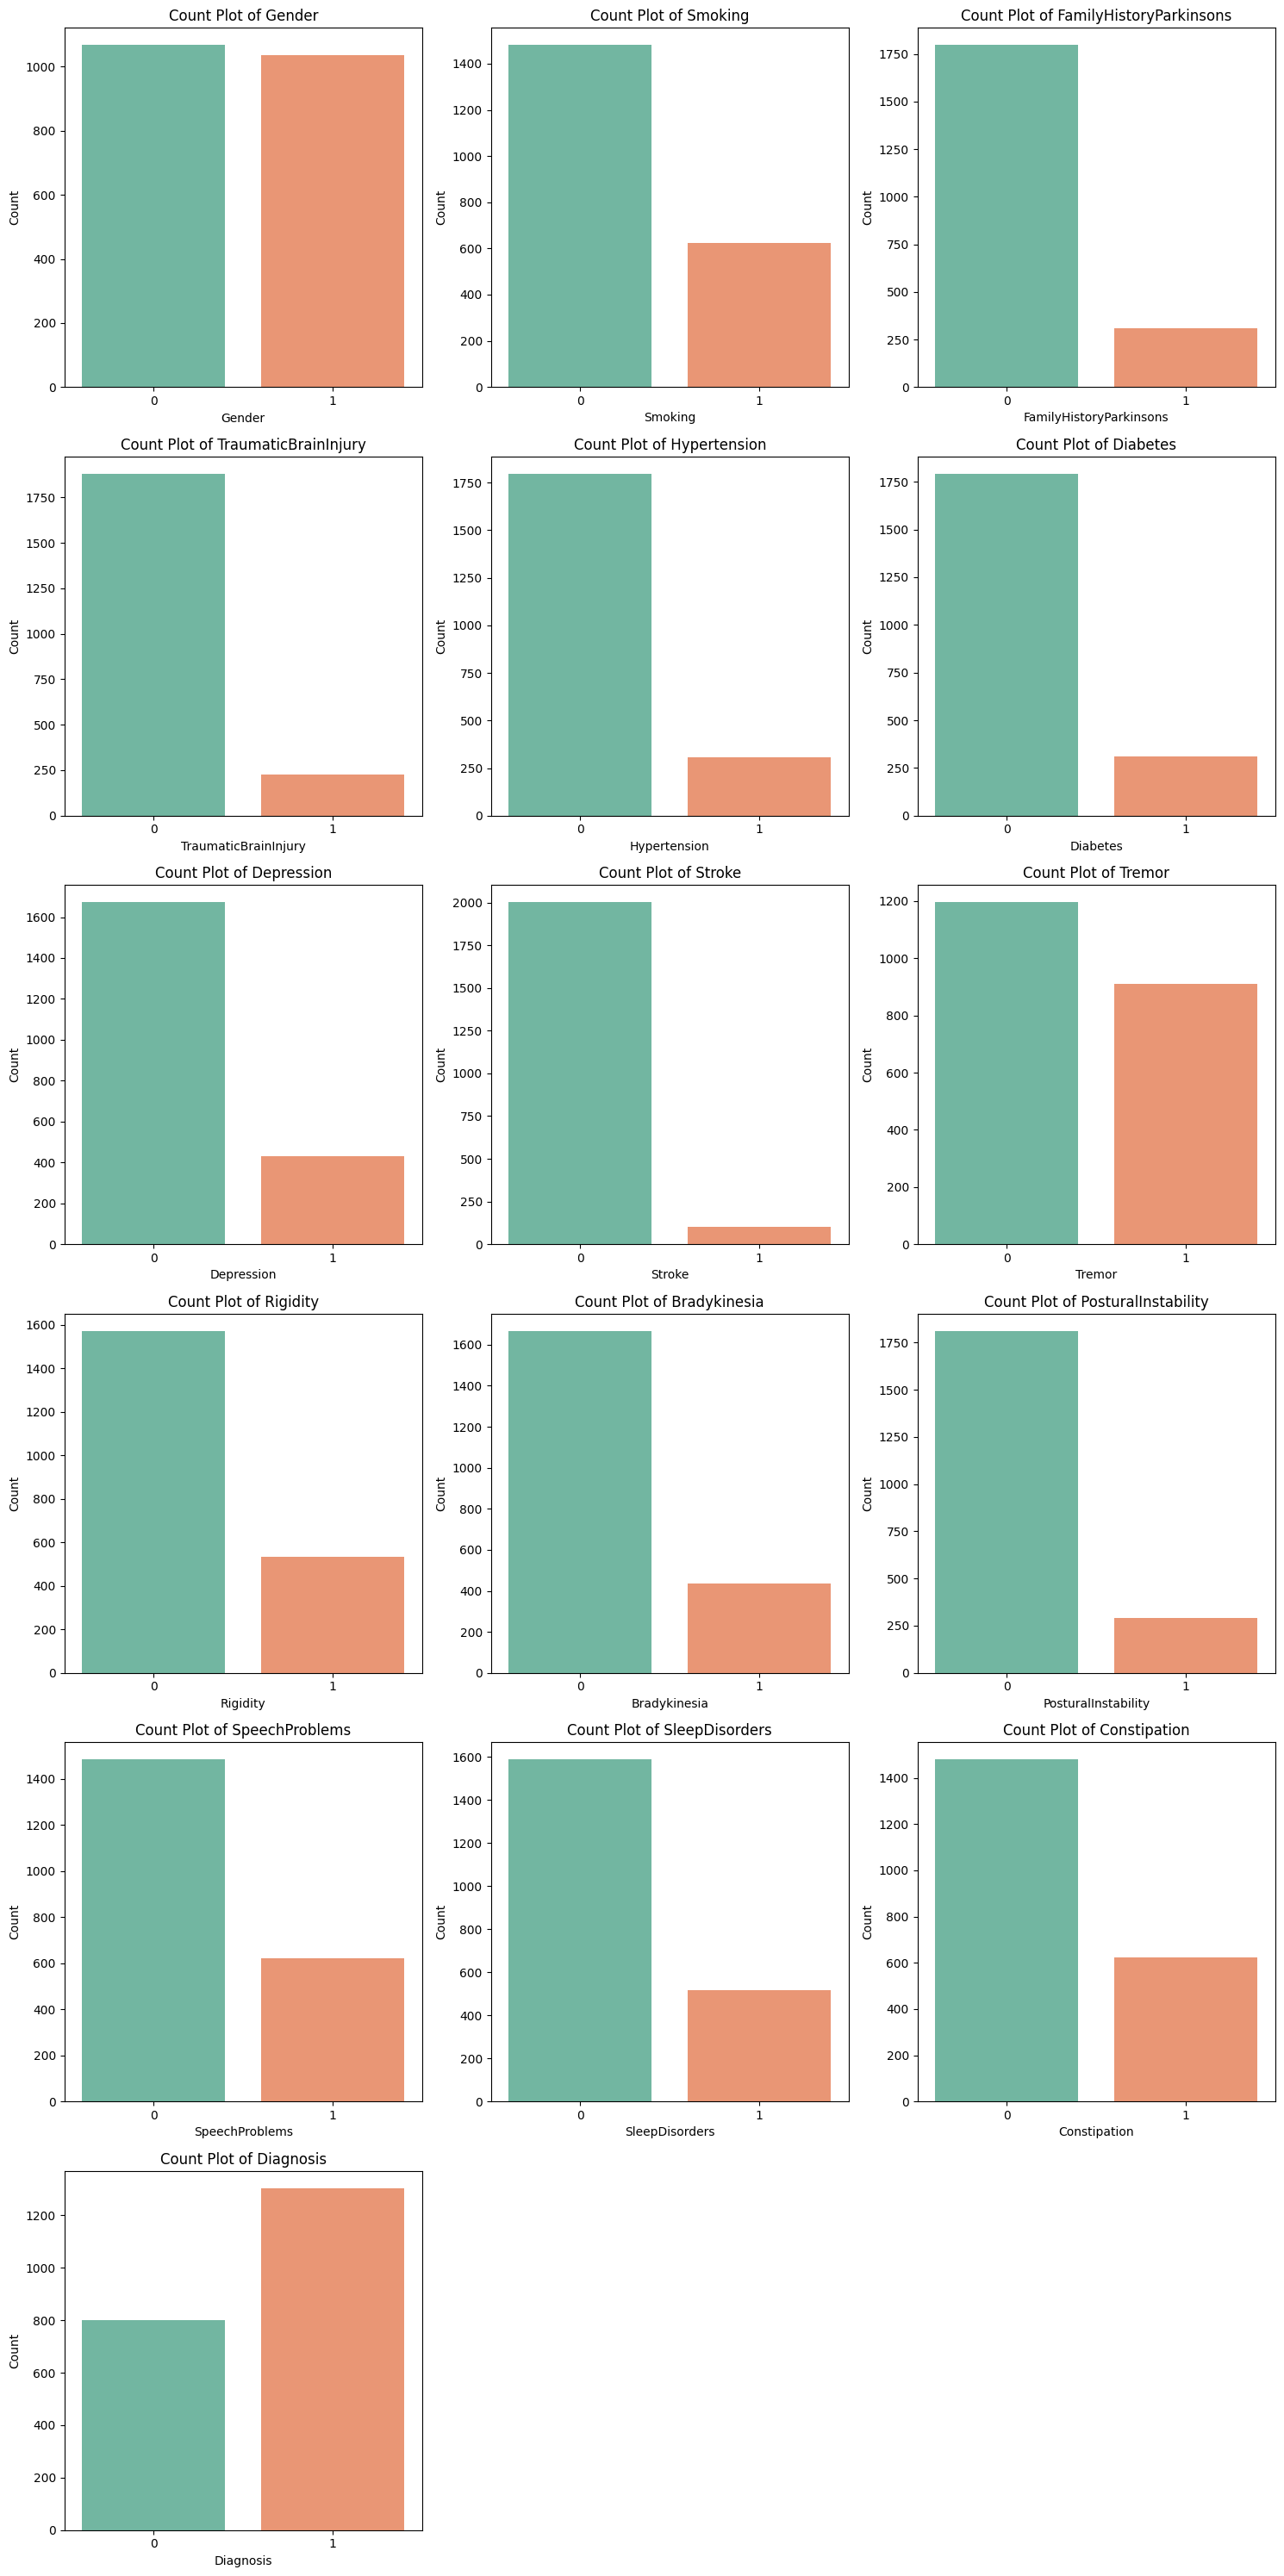

In [179]:
plot_binary_distribution(df, filtered_classification["binary"])


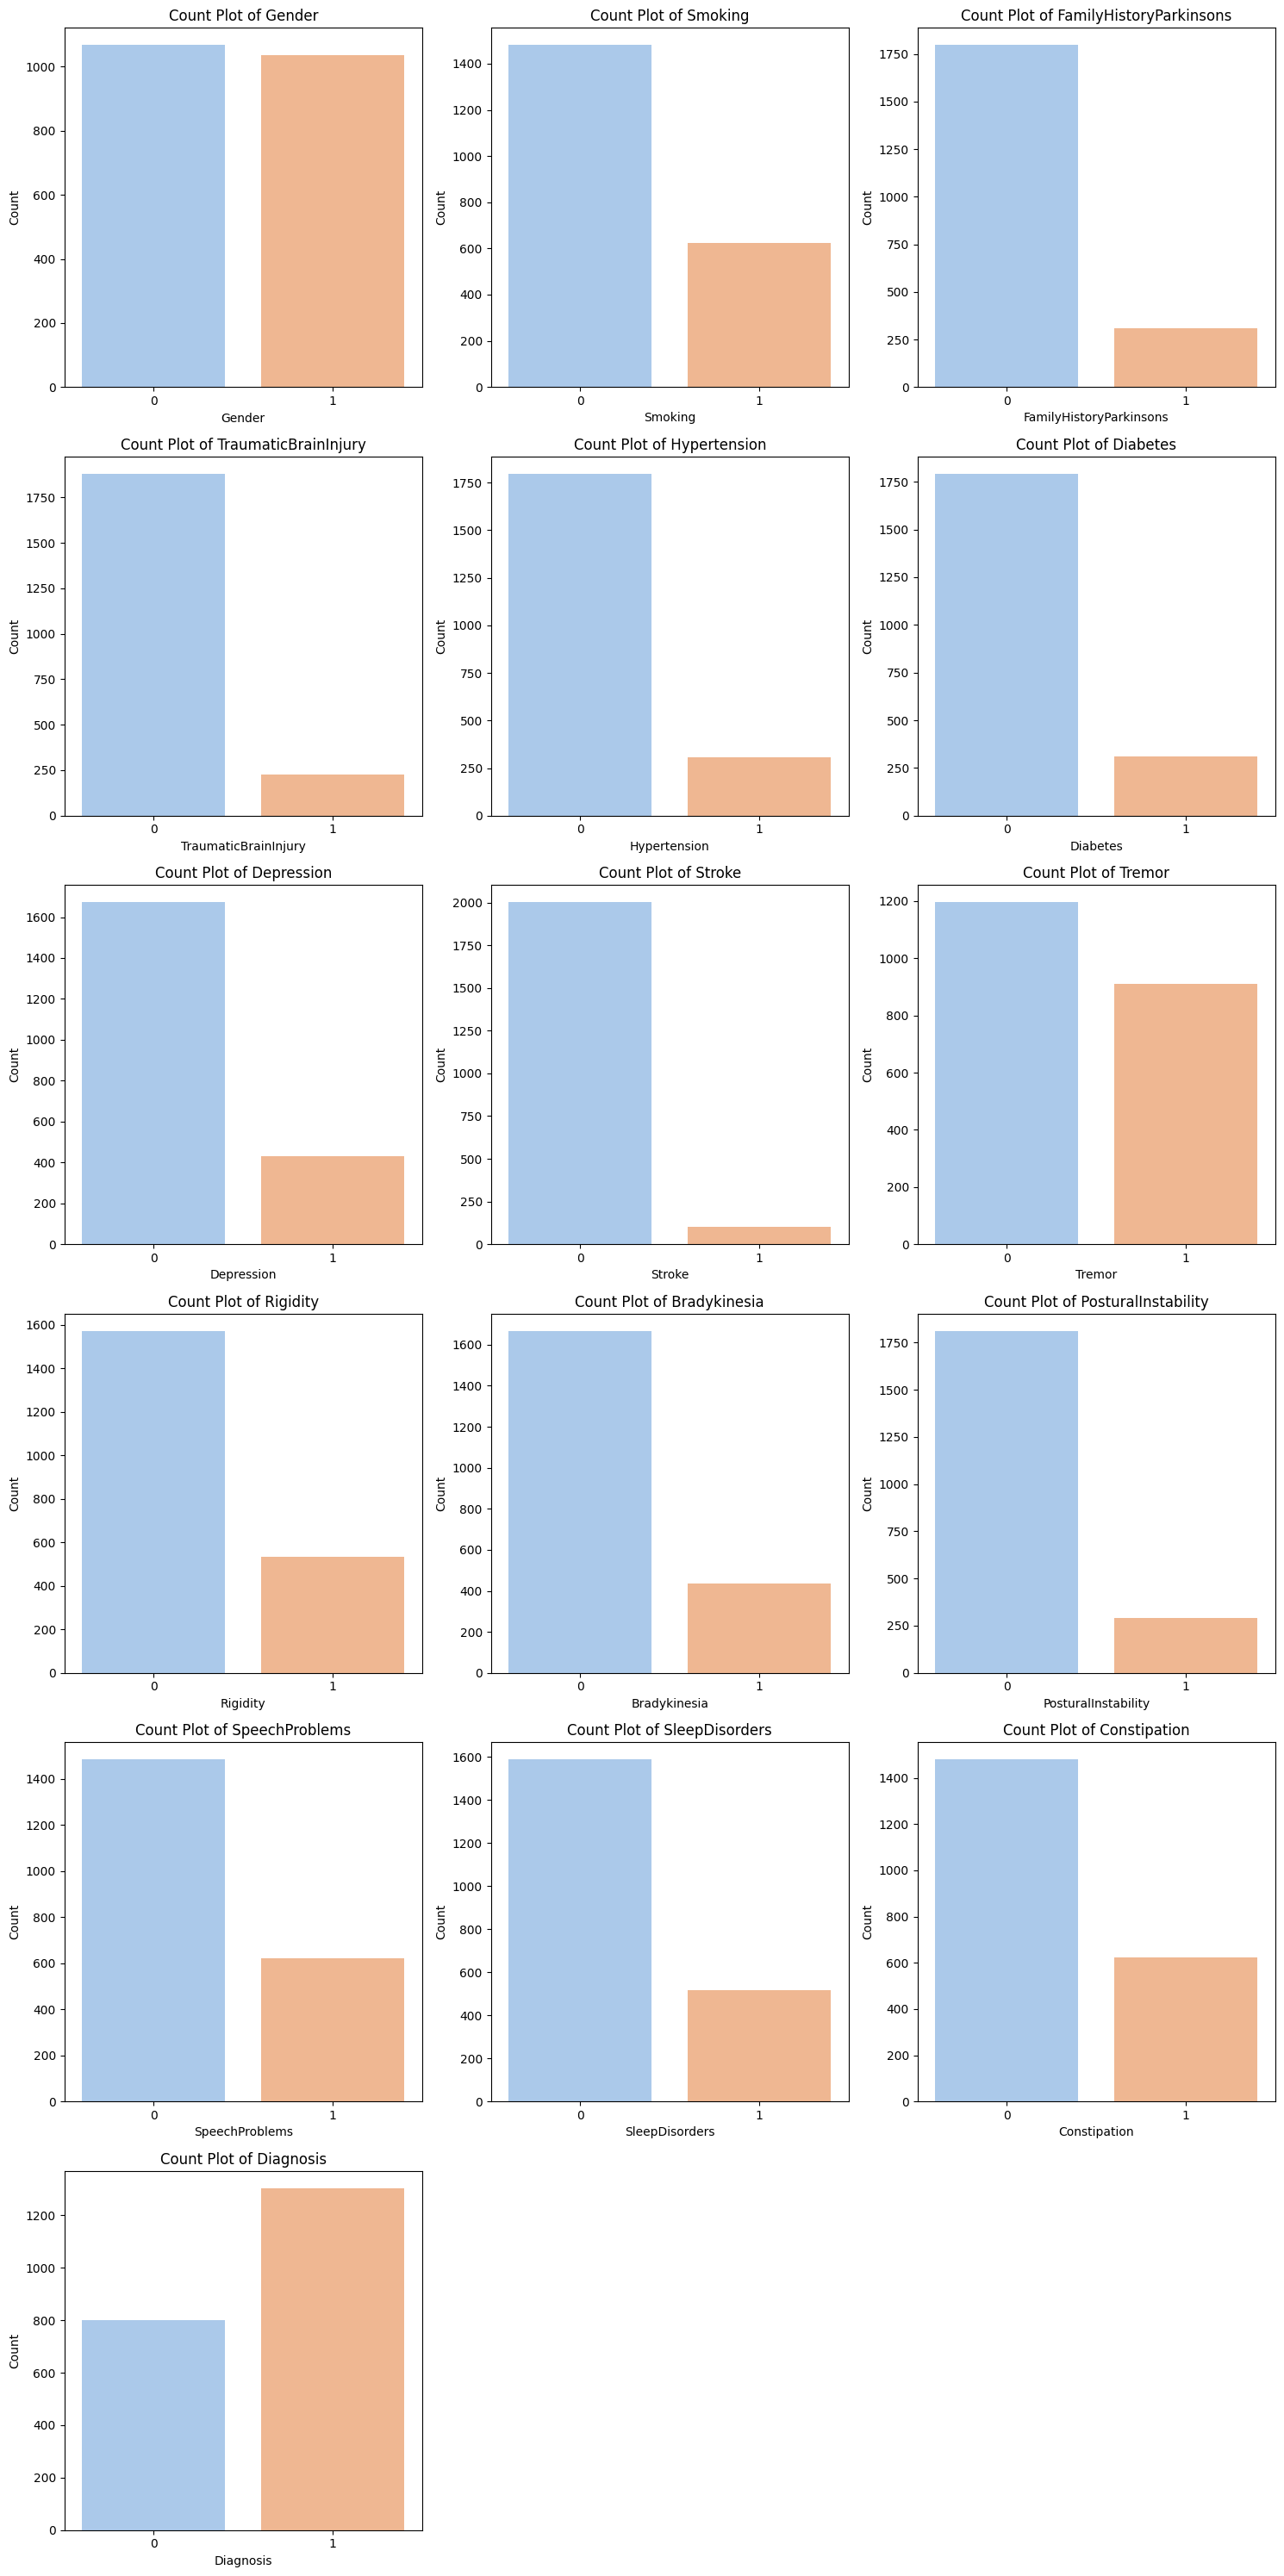

In [180]:
plot_binary_countplots(df, filtered_classification["binary"])


<ipython-input-178-d2d2644a338c>:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
<ipython-input-178-d2d2644a338c>:10: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[col], shade=True, color='blue', alpha=0.5, ax=axes[i])
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead

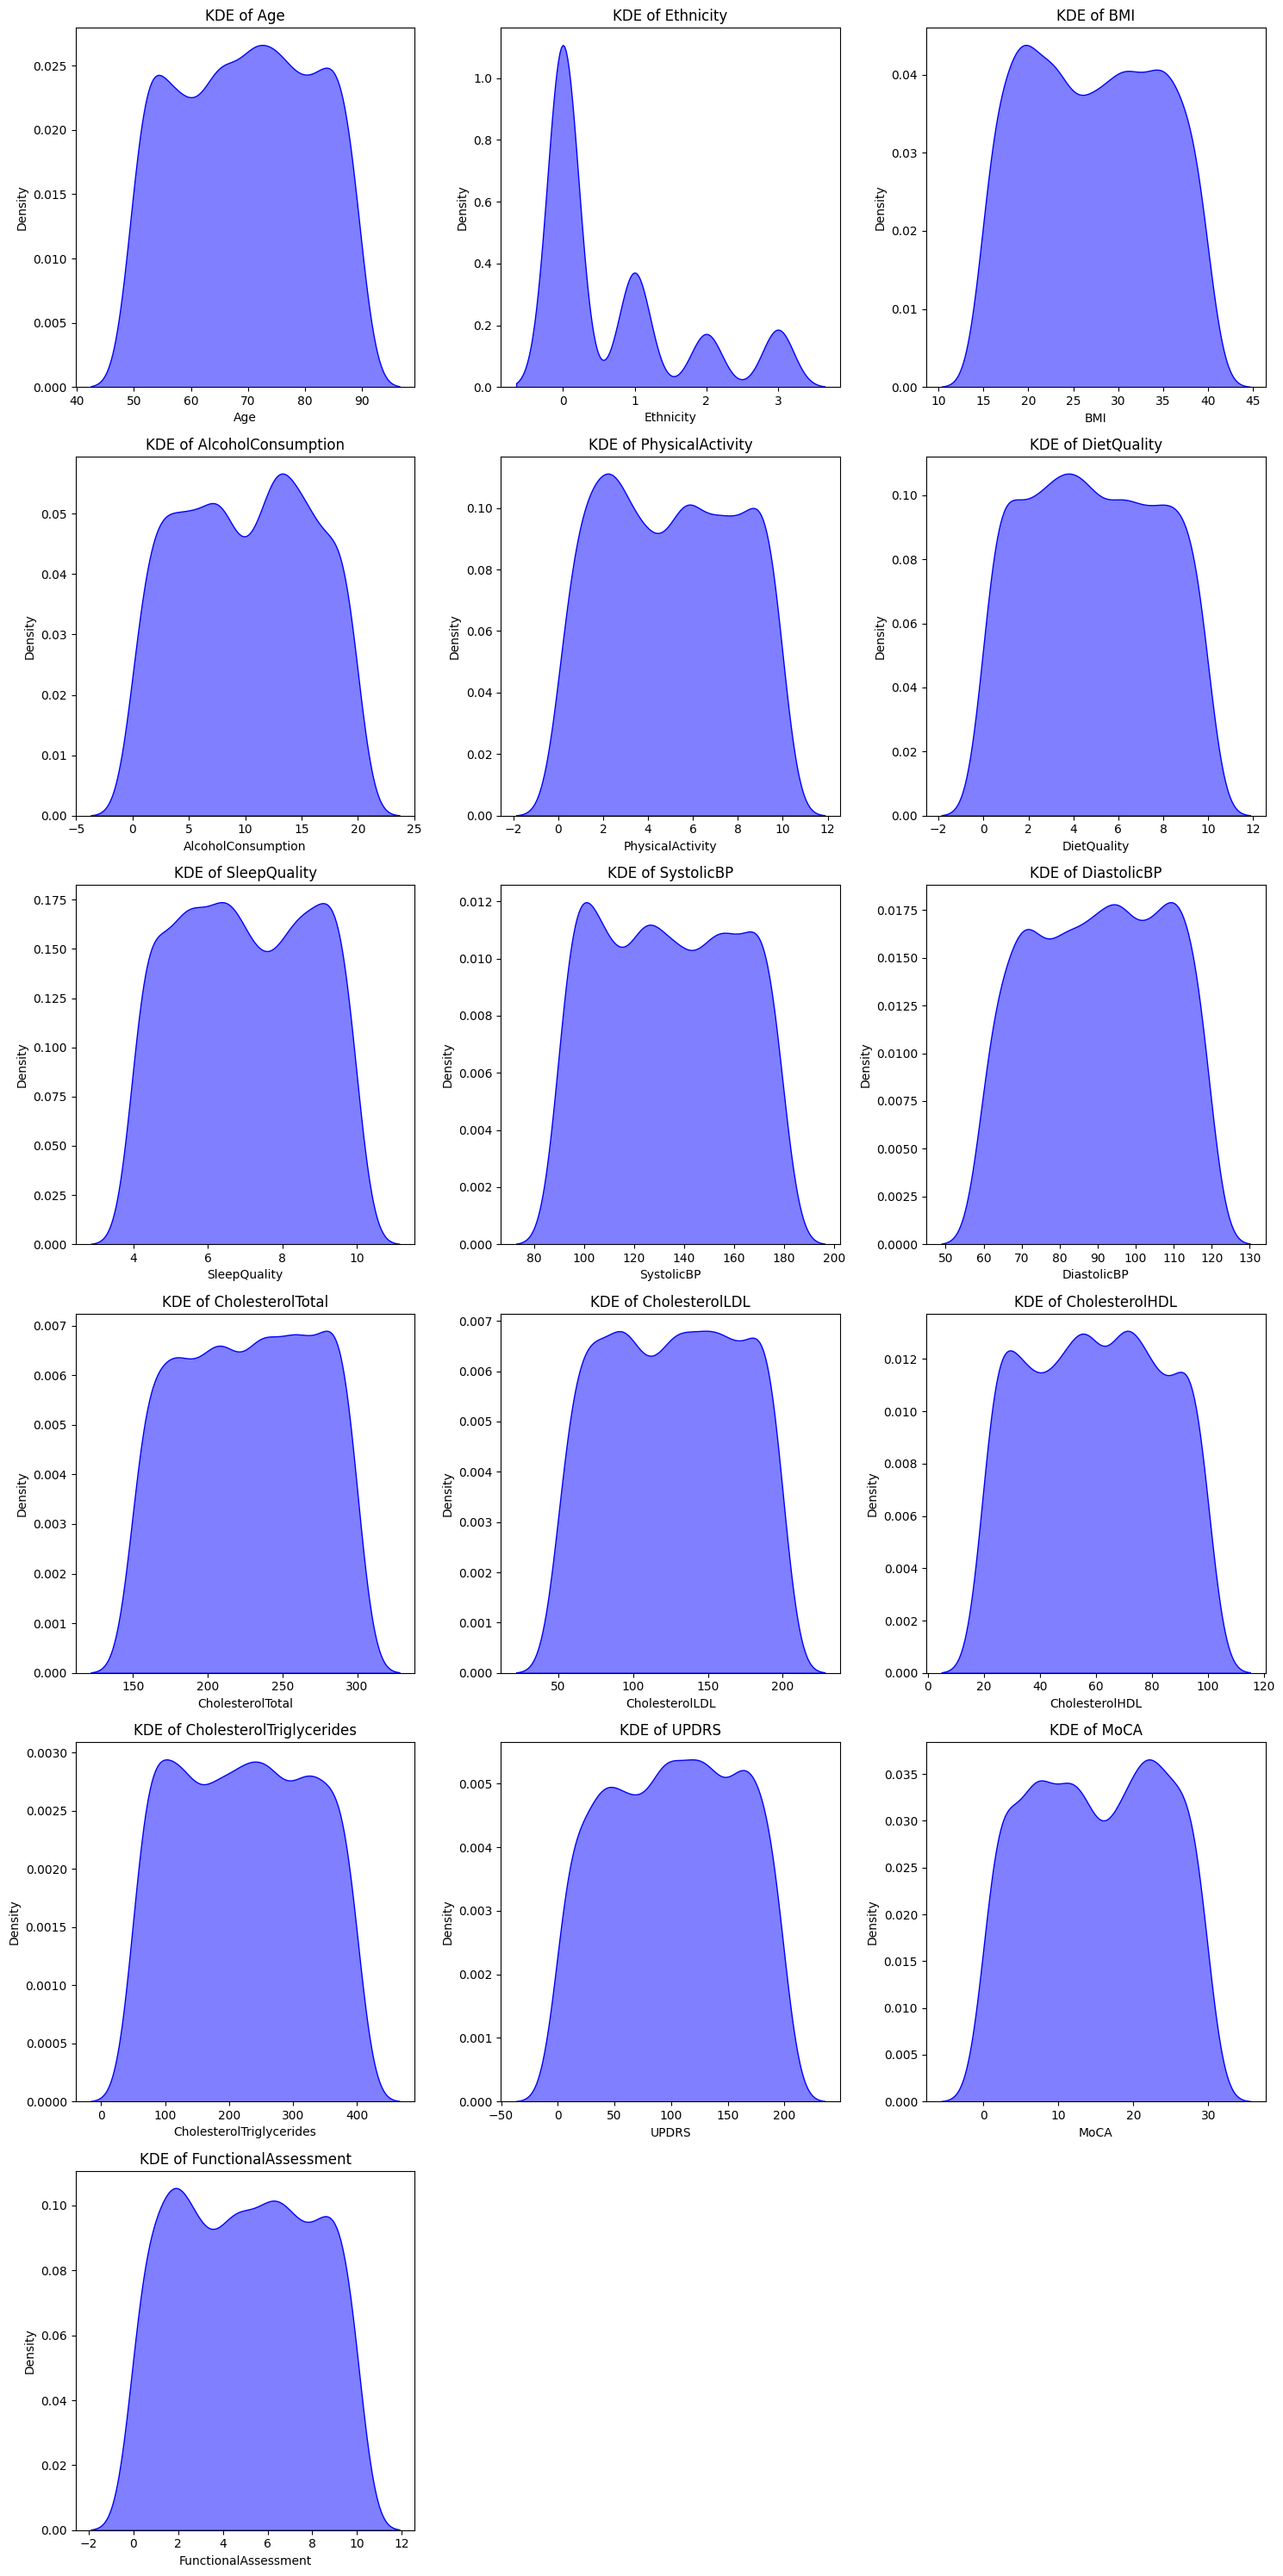

In [181]:
plot_kde(df, filtered_classification["numerical"])

In [182]:
def plot_barplot(df, categorical_cols):
    """Plot bar plots for categorical features to visualize the distribution of different categories."""
    num_plots = len(categorical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0) 
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten() 
    
    for i, col in enumerate(categorical_cols):
        sns.countplot(x=df[col], palette="Set2", ax=axes[i])
        axes[i].set_title(f"Bar Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")
    
    for i in range(num_plots, len(axes)):
        axes[i].axis('off') 
    
    plt.tight_layout()
    plt.show()

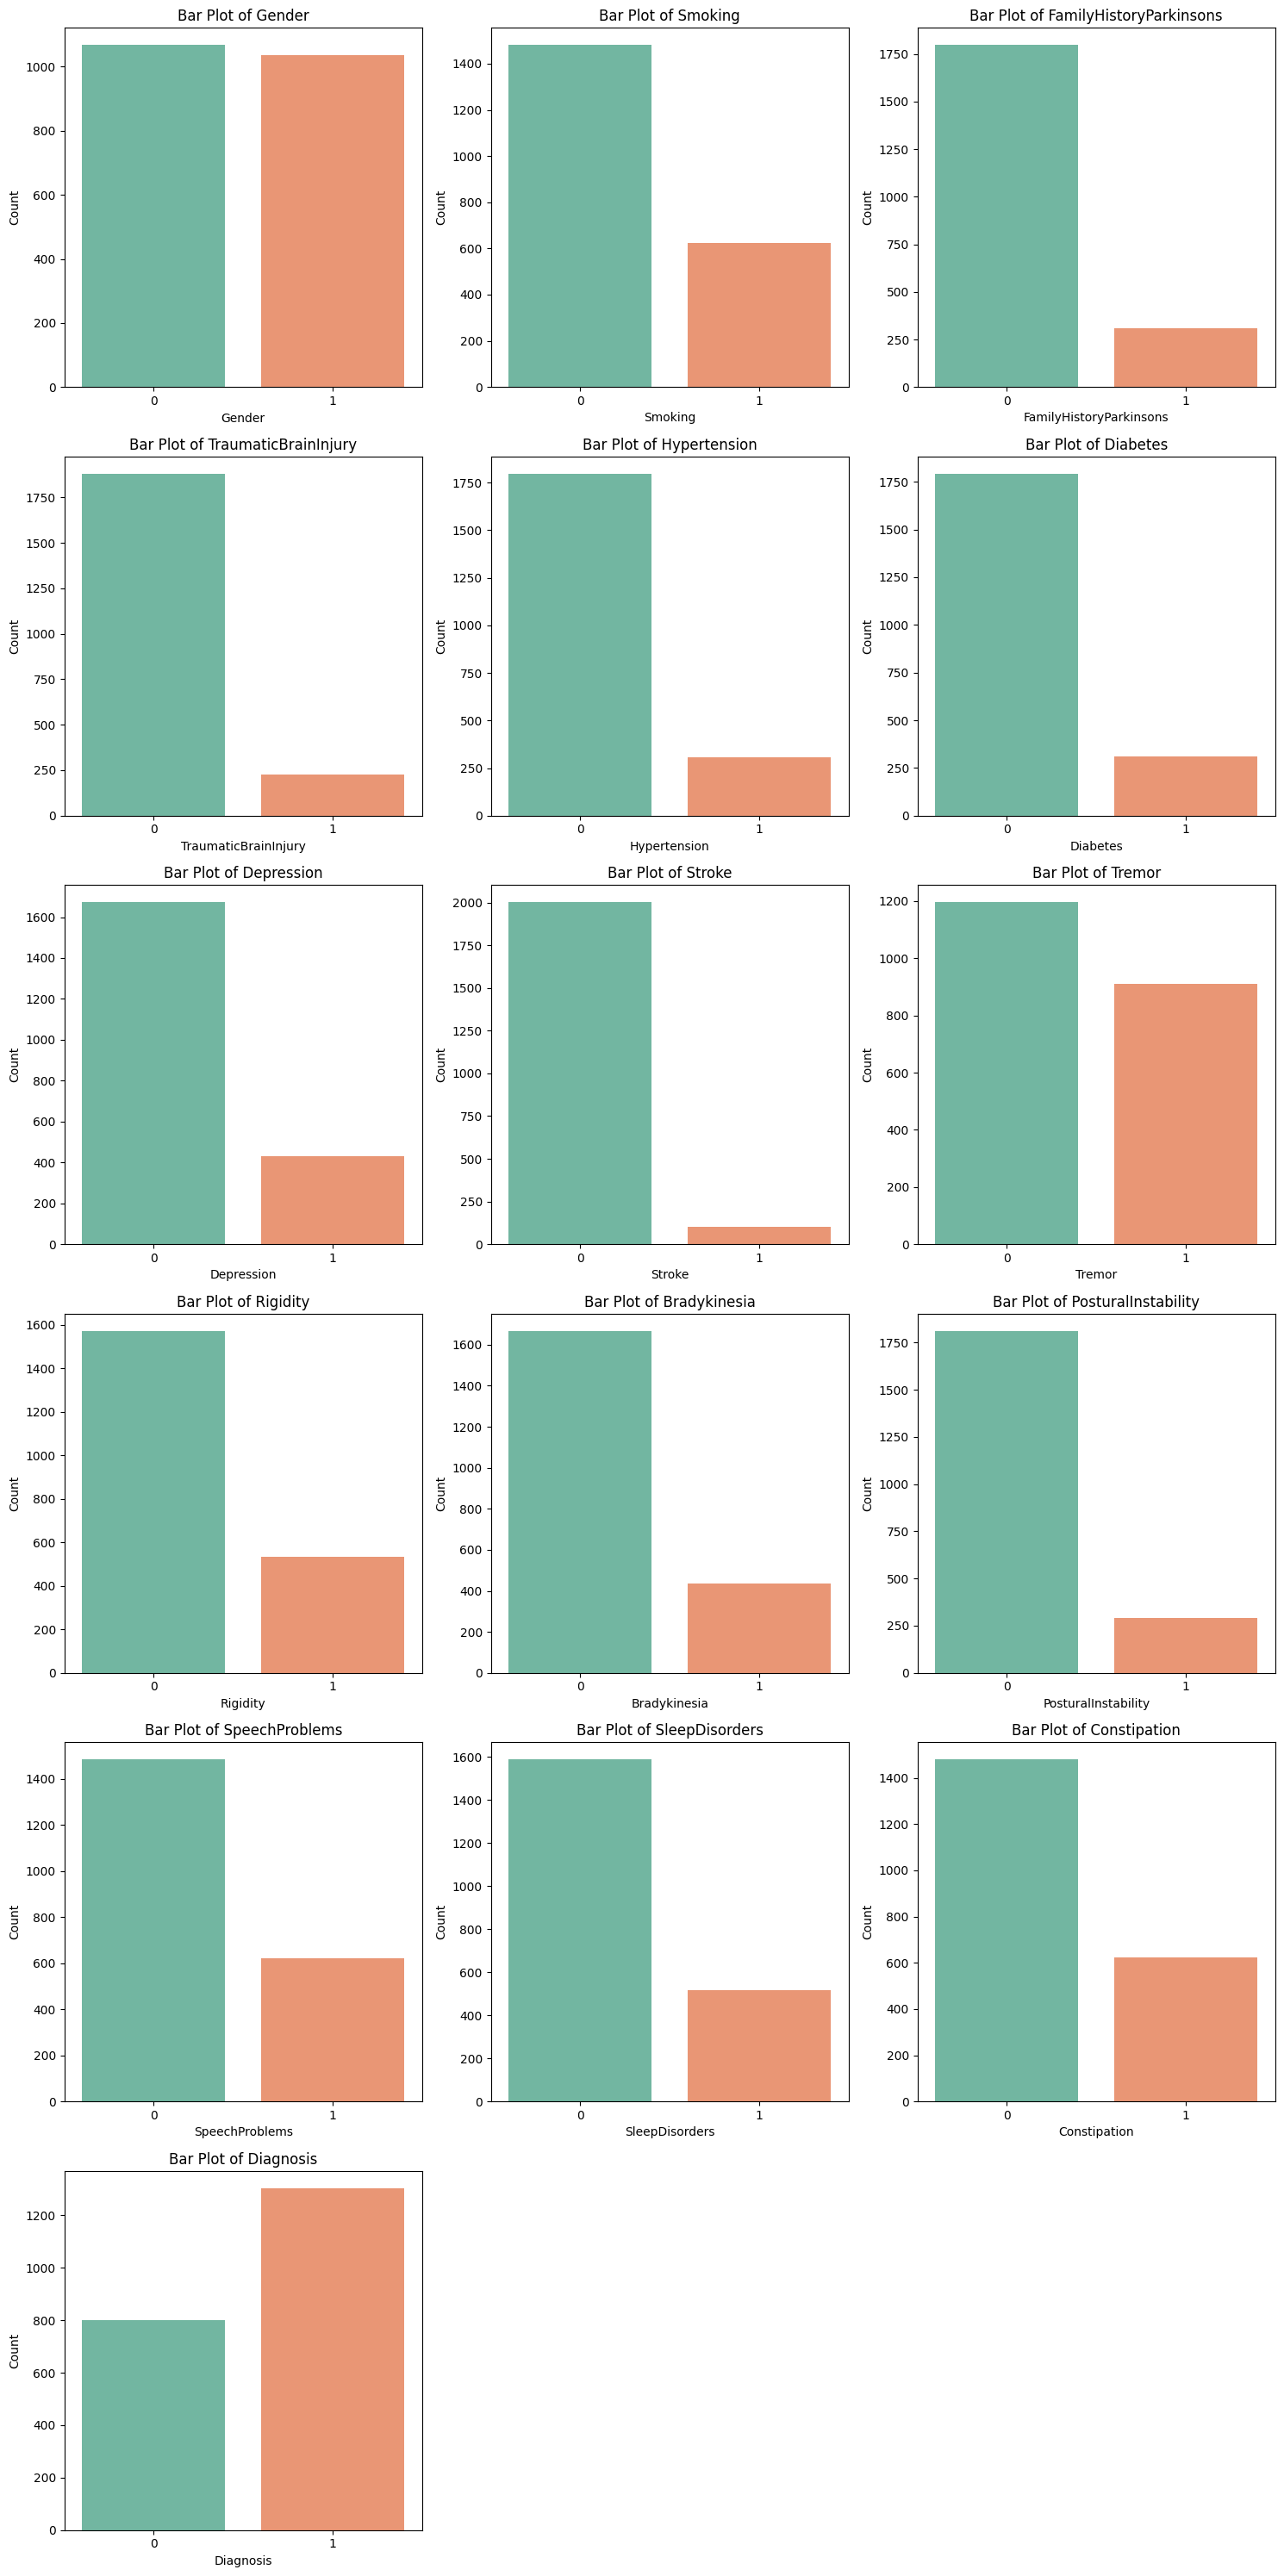

In [183]:
plot_barplot(df, filtered_classification["binary"])

In [184]:
# At Risk (Binary)
# Check for class imbalance
df['Diagnosis'].value_counts()/len(df)

Diagnosis
1    0.619477
0    0.380523
Name: count, dtype: float64

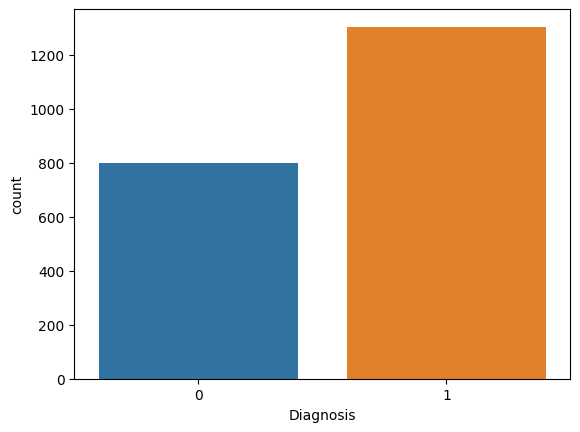

In [185]:
sns.countplot(x='Diagnosis',data=df)
plt.show()

# 5. Outlier Detection

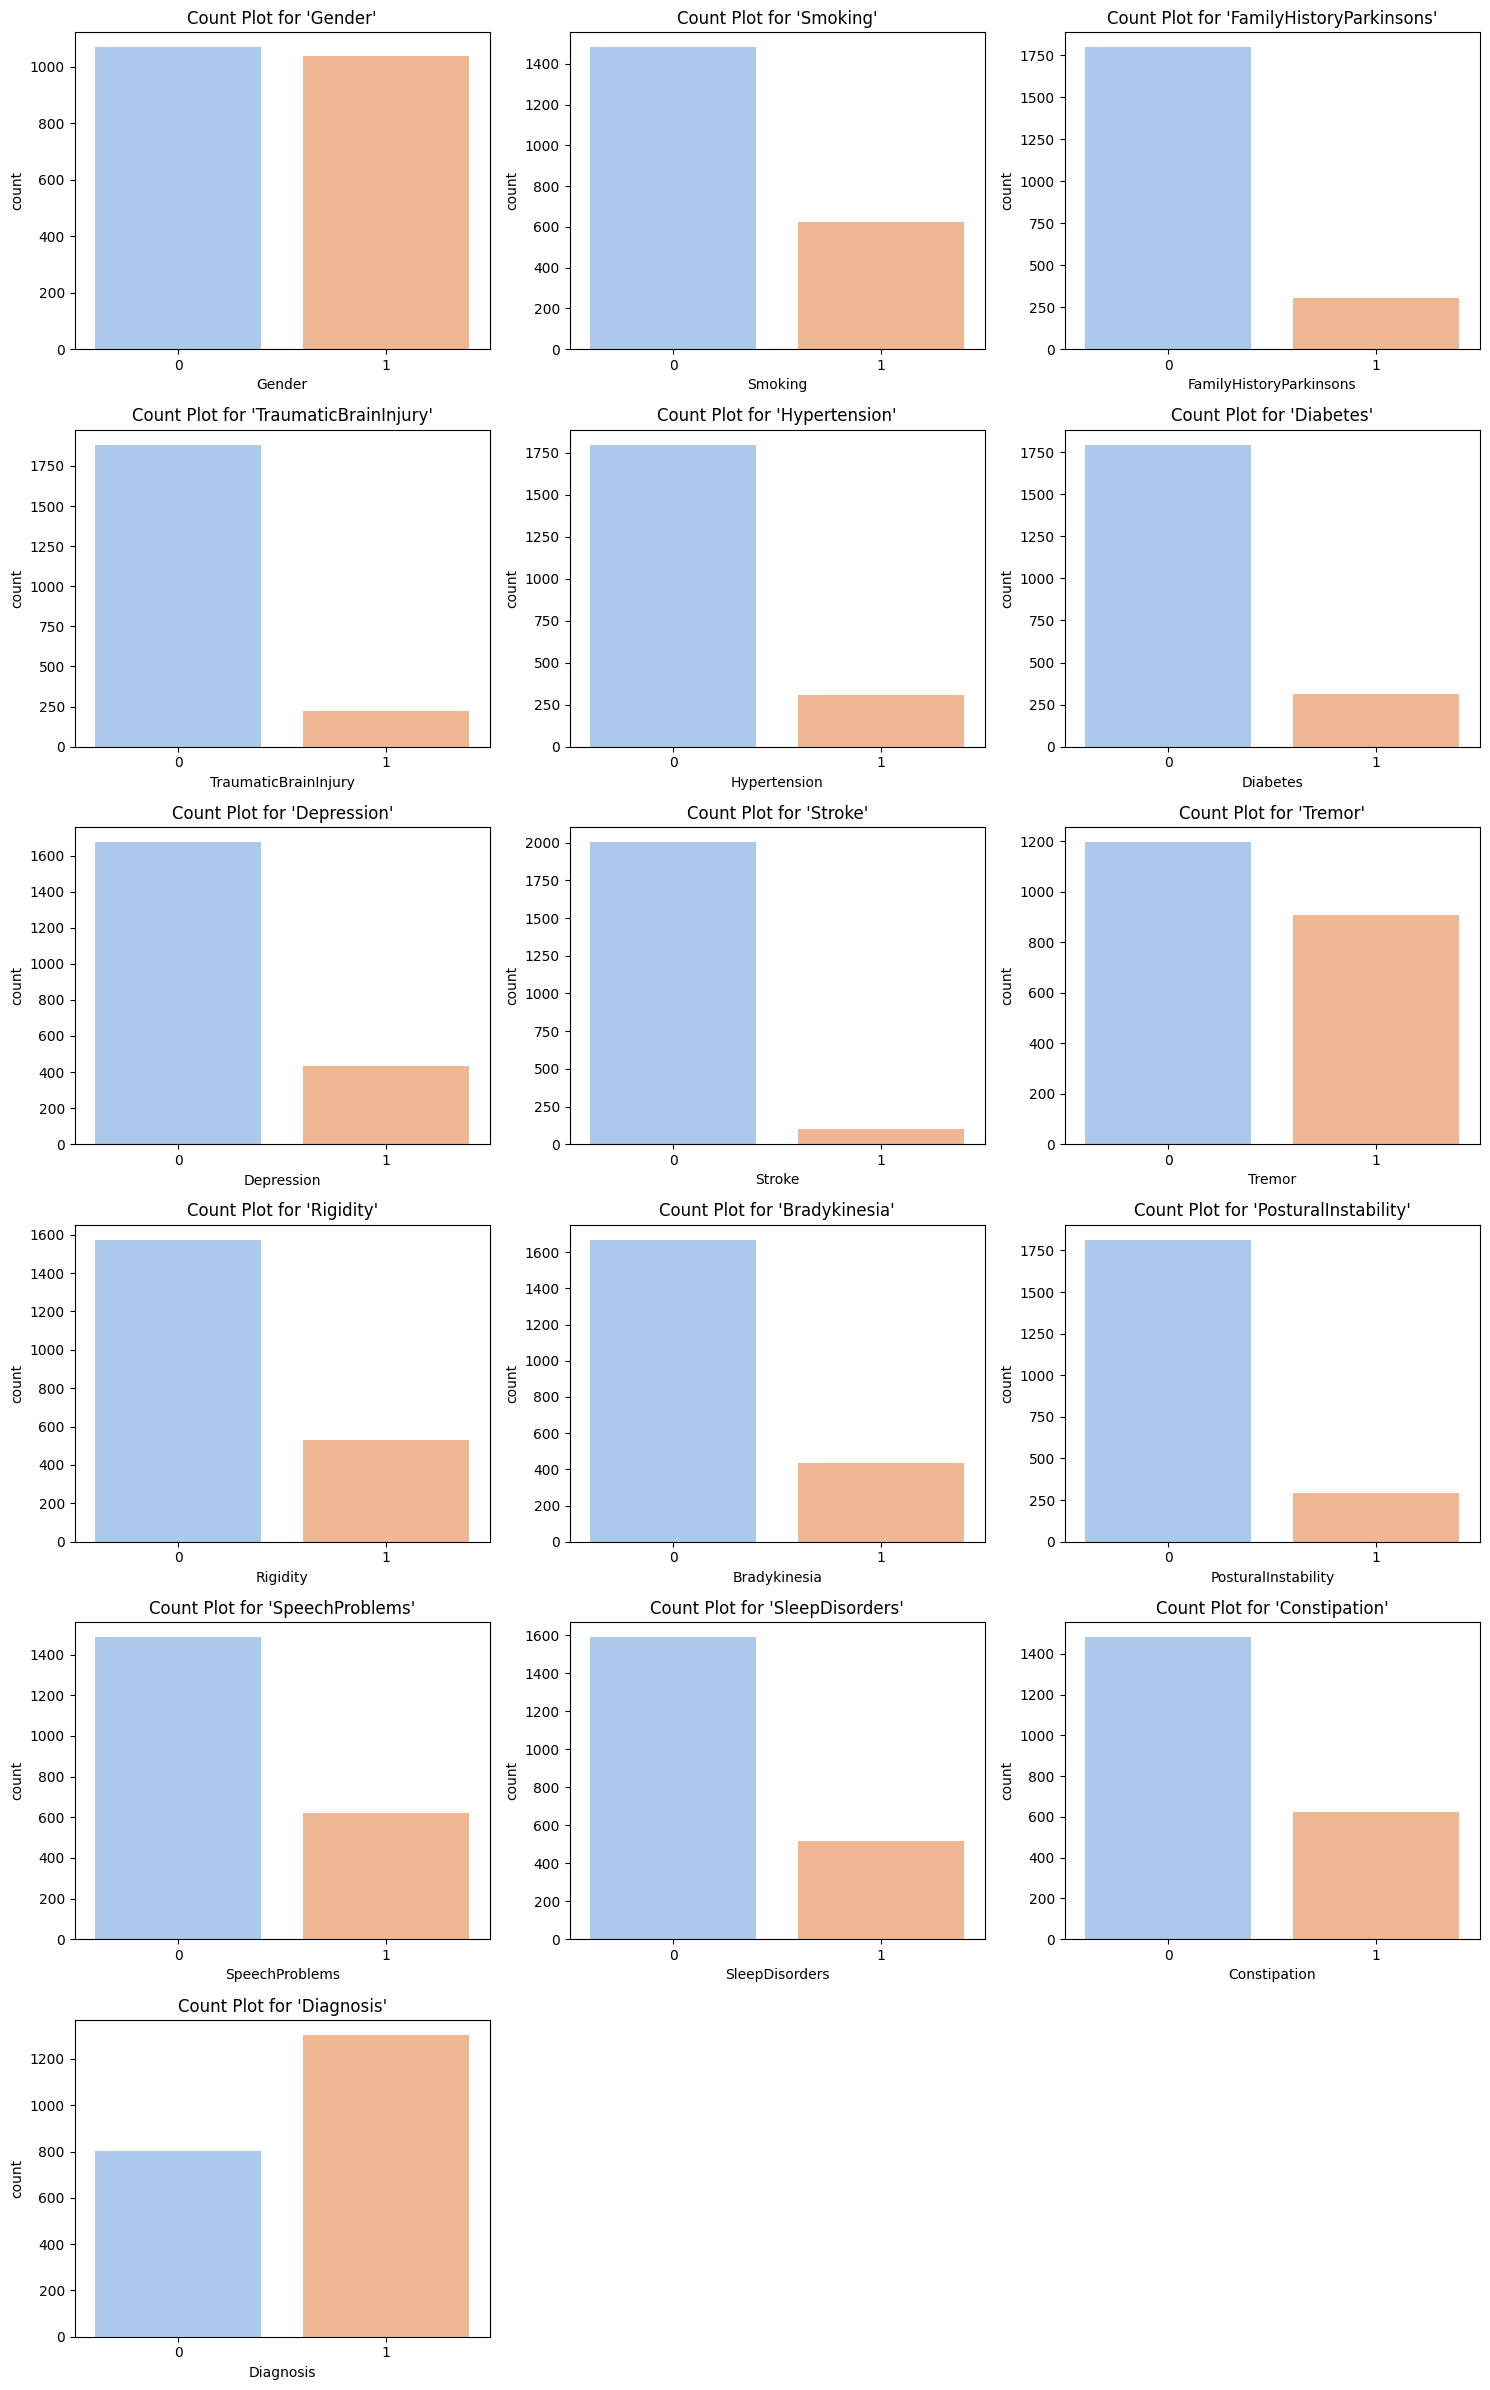

In [186]:


# Select binary columns (only those with 2 unique values: 0 and 1)
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and df[col].dtype in ['int64', 'float64']]

# Plot count plots for each binary feature
num_plots = len(binary_cols)
num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 4))
axes = axes.flatten()

for i, col in enumerate(binary_cols):
    sns.countplot(x=col, data=df, ax=axes[i], palette='pastel')
    axes[i].set_title(f"Count Plot for '{col}'")
    axes[i].set_xticks([0, 1])
    
# Hide unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [187]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distributions."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for j in range(num_plots, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


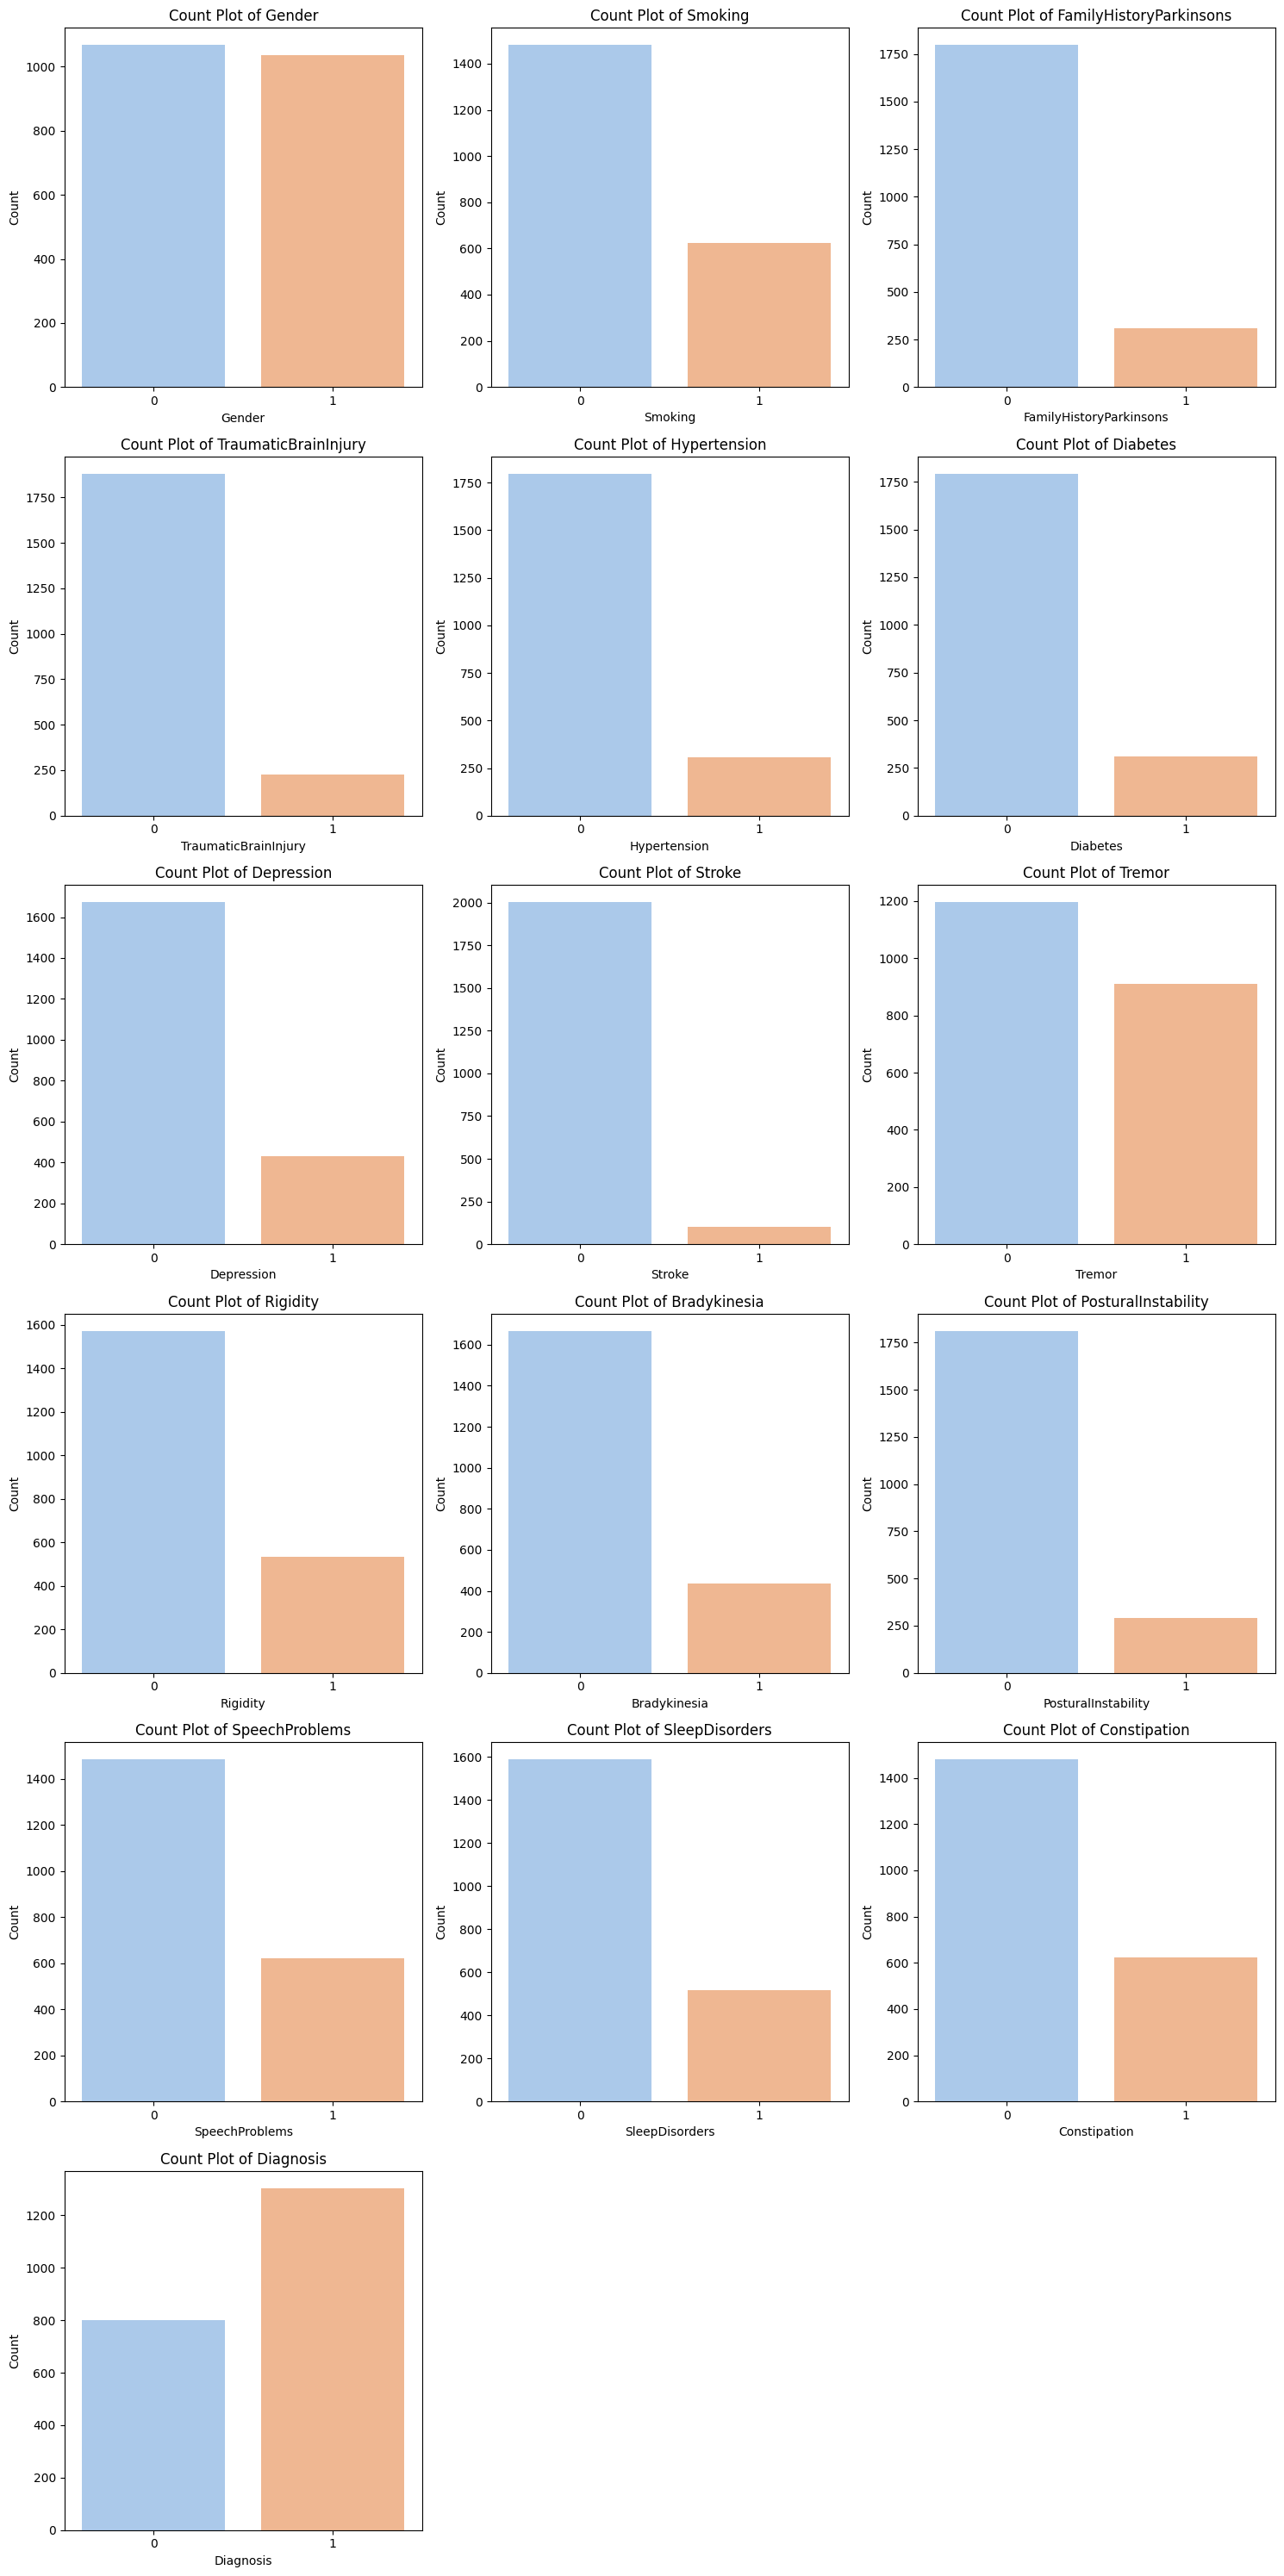

In [188]:
plot_binary_countplots(df, filtered_classification["binary"])


In [189]:
def plot_boxplots(df, numerical_cols):
    """Plot box plots for numerical features to visualize outliers."""
    num_plots = len(numerical_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)
    
    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()
    
    for i, col in enumerate(numerical_cols):
        sns.boxplot(x=df[col], ax=axes[i], color='lightcoral')
        axes[i].set_title(f"Boxplot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [190]:
def plot_violinplots(df, numerical_cols):
    """Plot violin plots for numerical features to visualize distribution and outliers."""
    num_plots = len(numerical_cols)
    cols_per_row = 3 
    rows = (num_plots // cols_per_row) + (num_plots % cols_per_row > 0)  

    fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, 5 * rows))
    axes = axes.flatten() 

    for i, col in enumerate(numerical_cols):
        sns.violinplot(x=df[col], ax=axes[i], color='teal')
        axes[i].set_title(f"Violin Plot of {col}")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

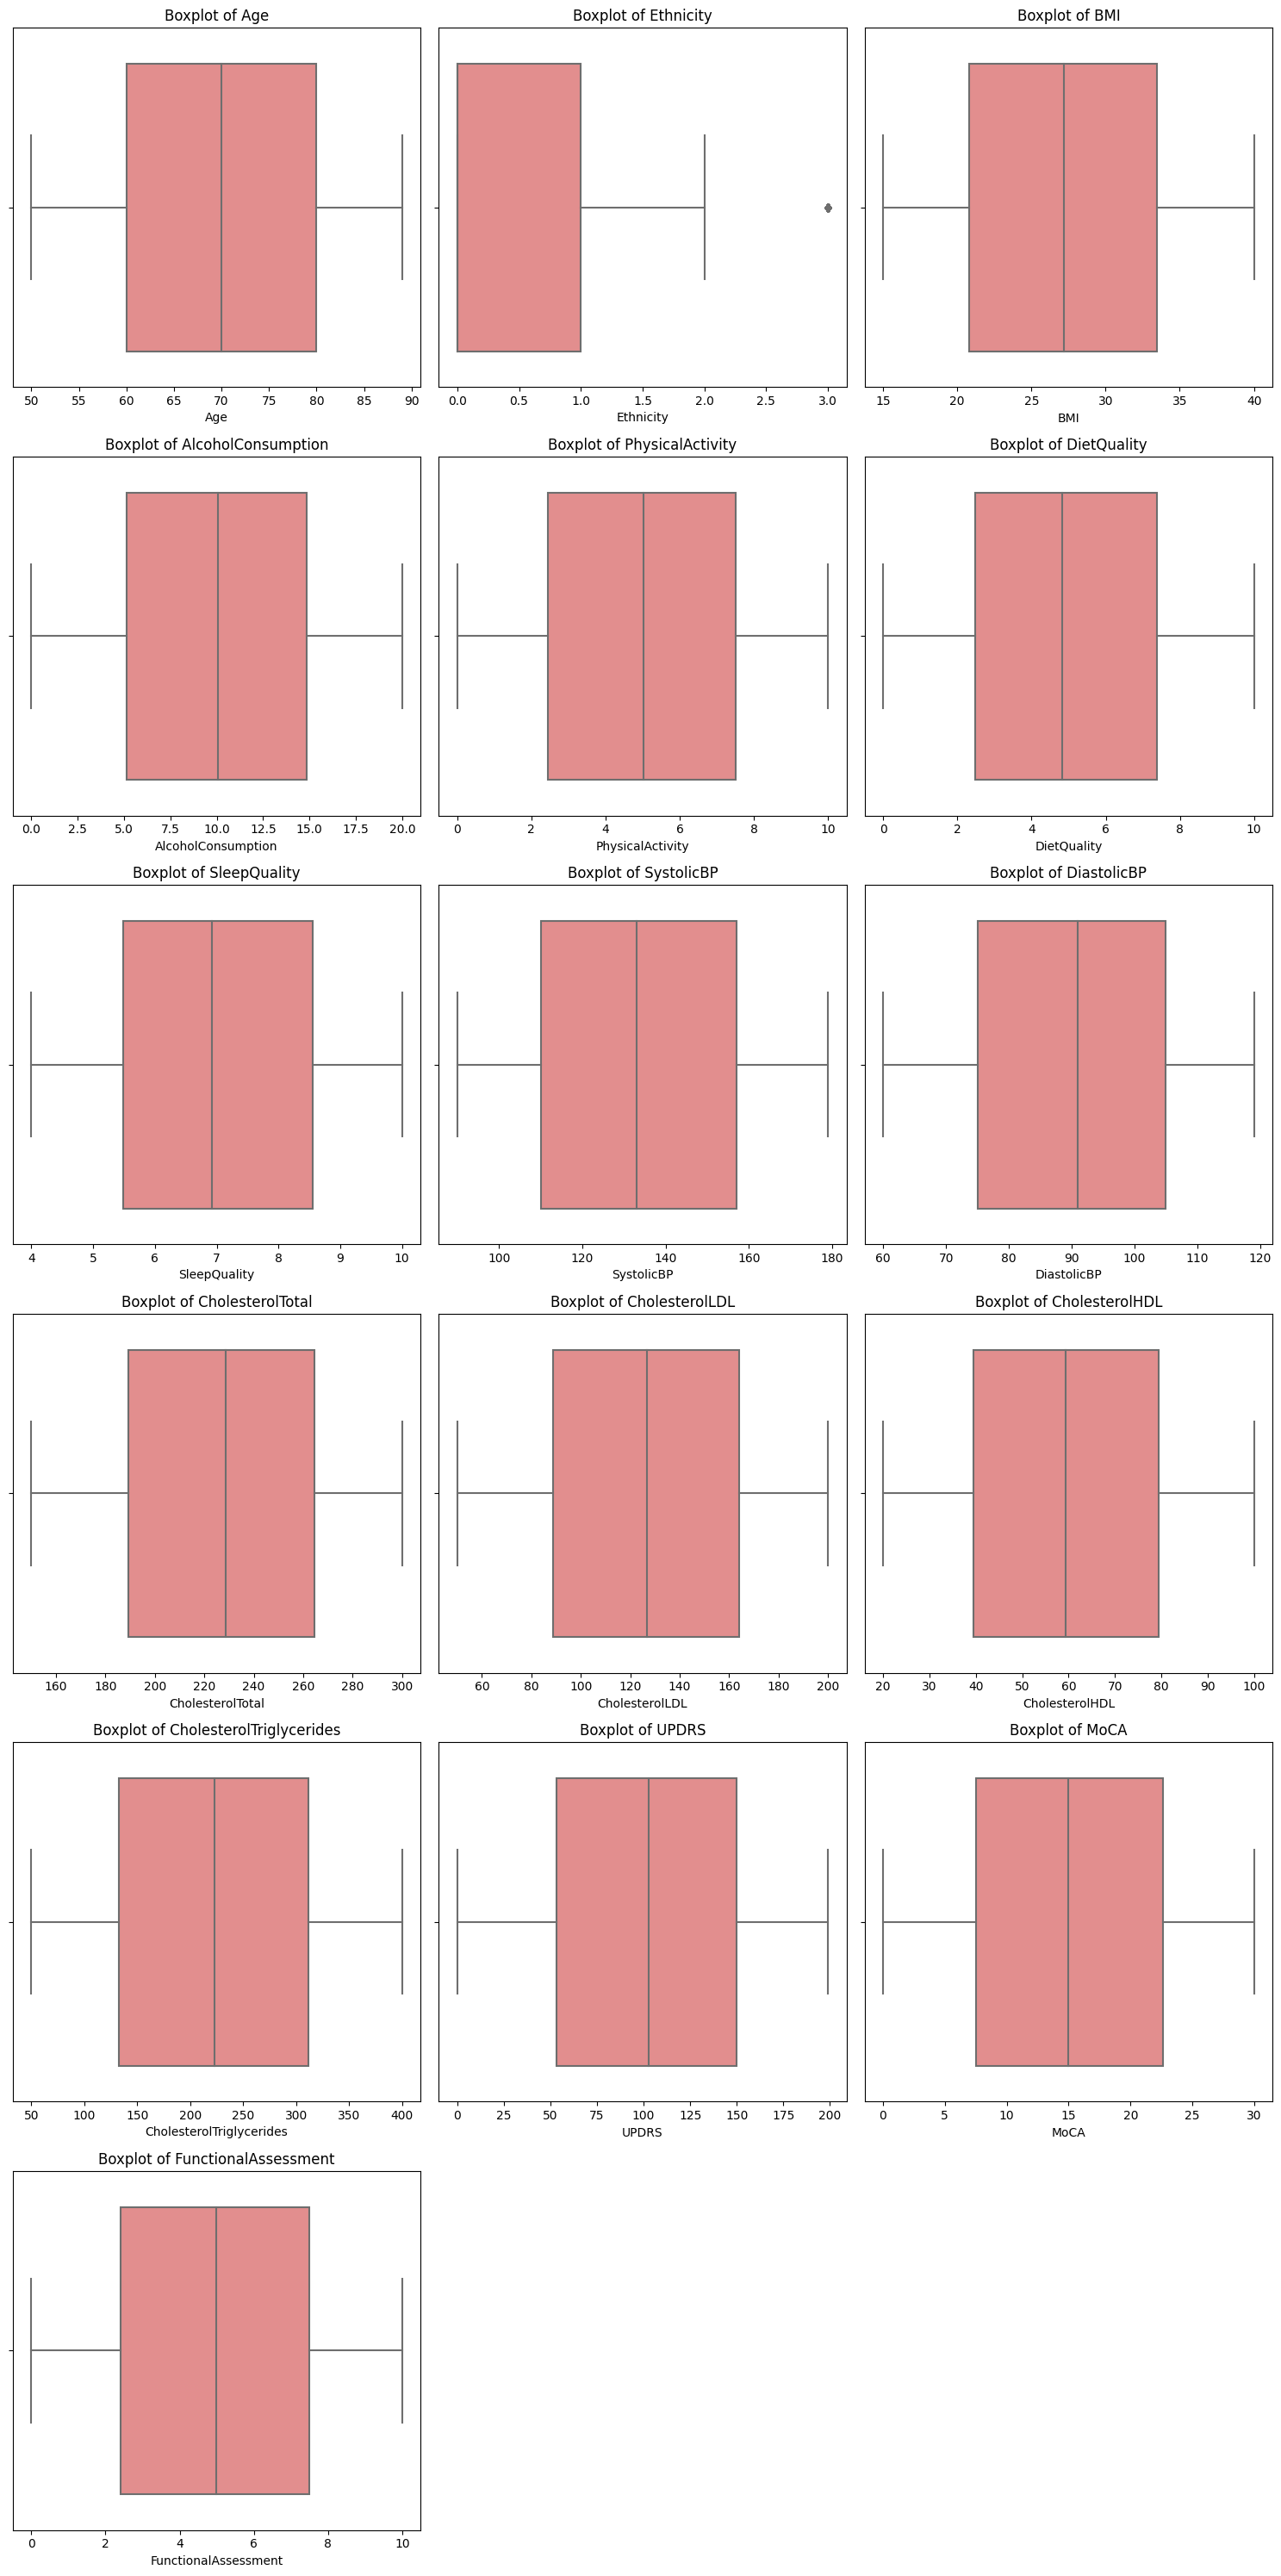

In [191]:
plot_boxplots(df, filtered_classification["numerical"])

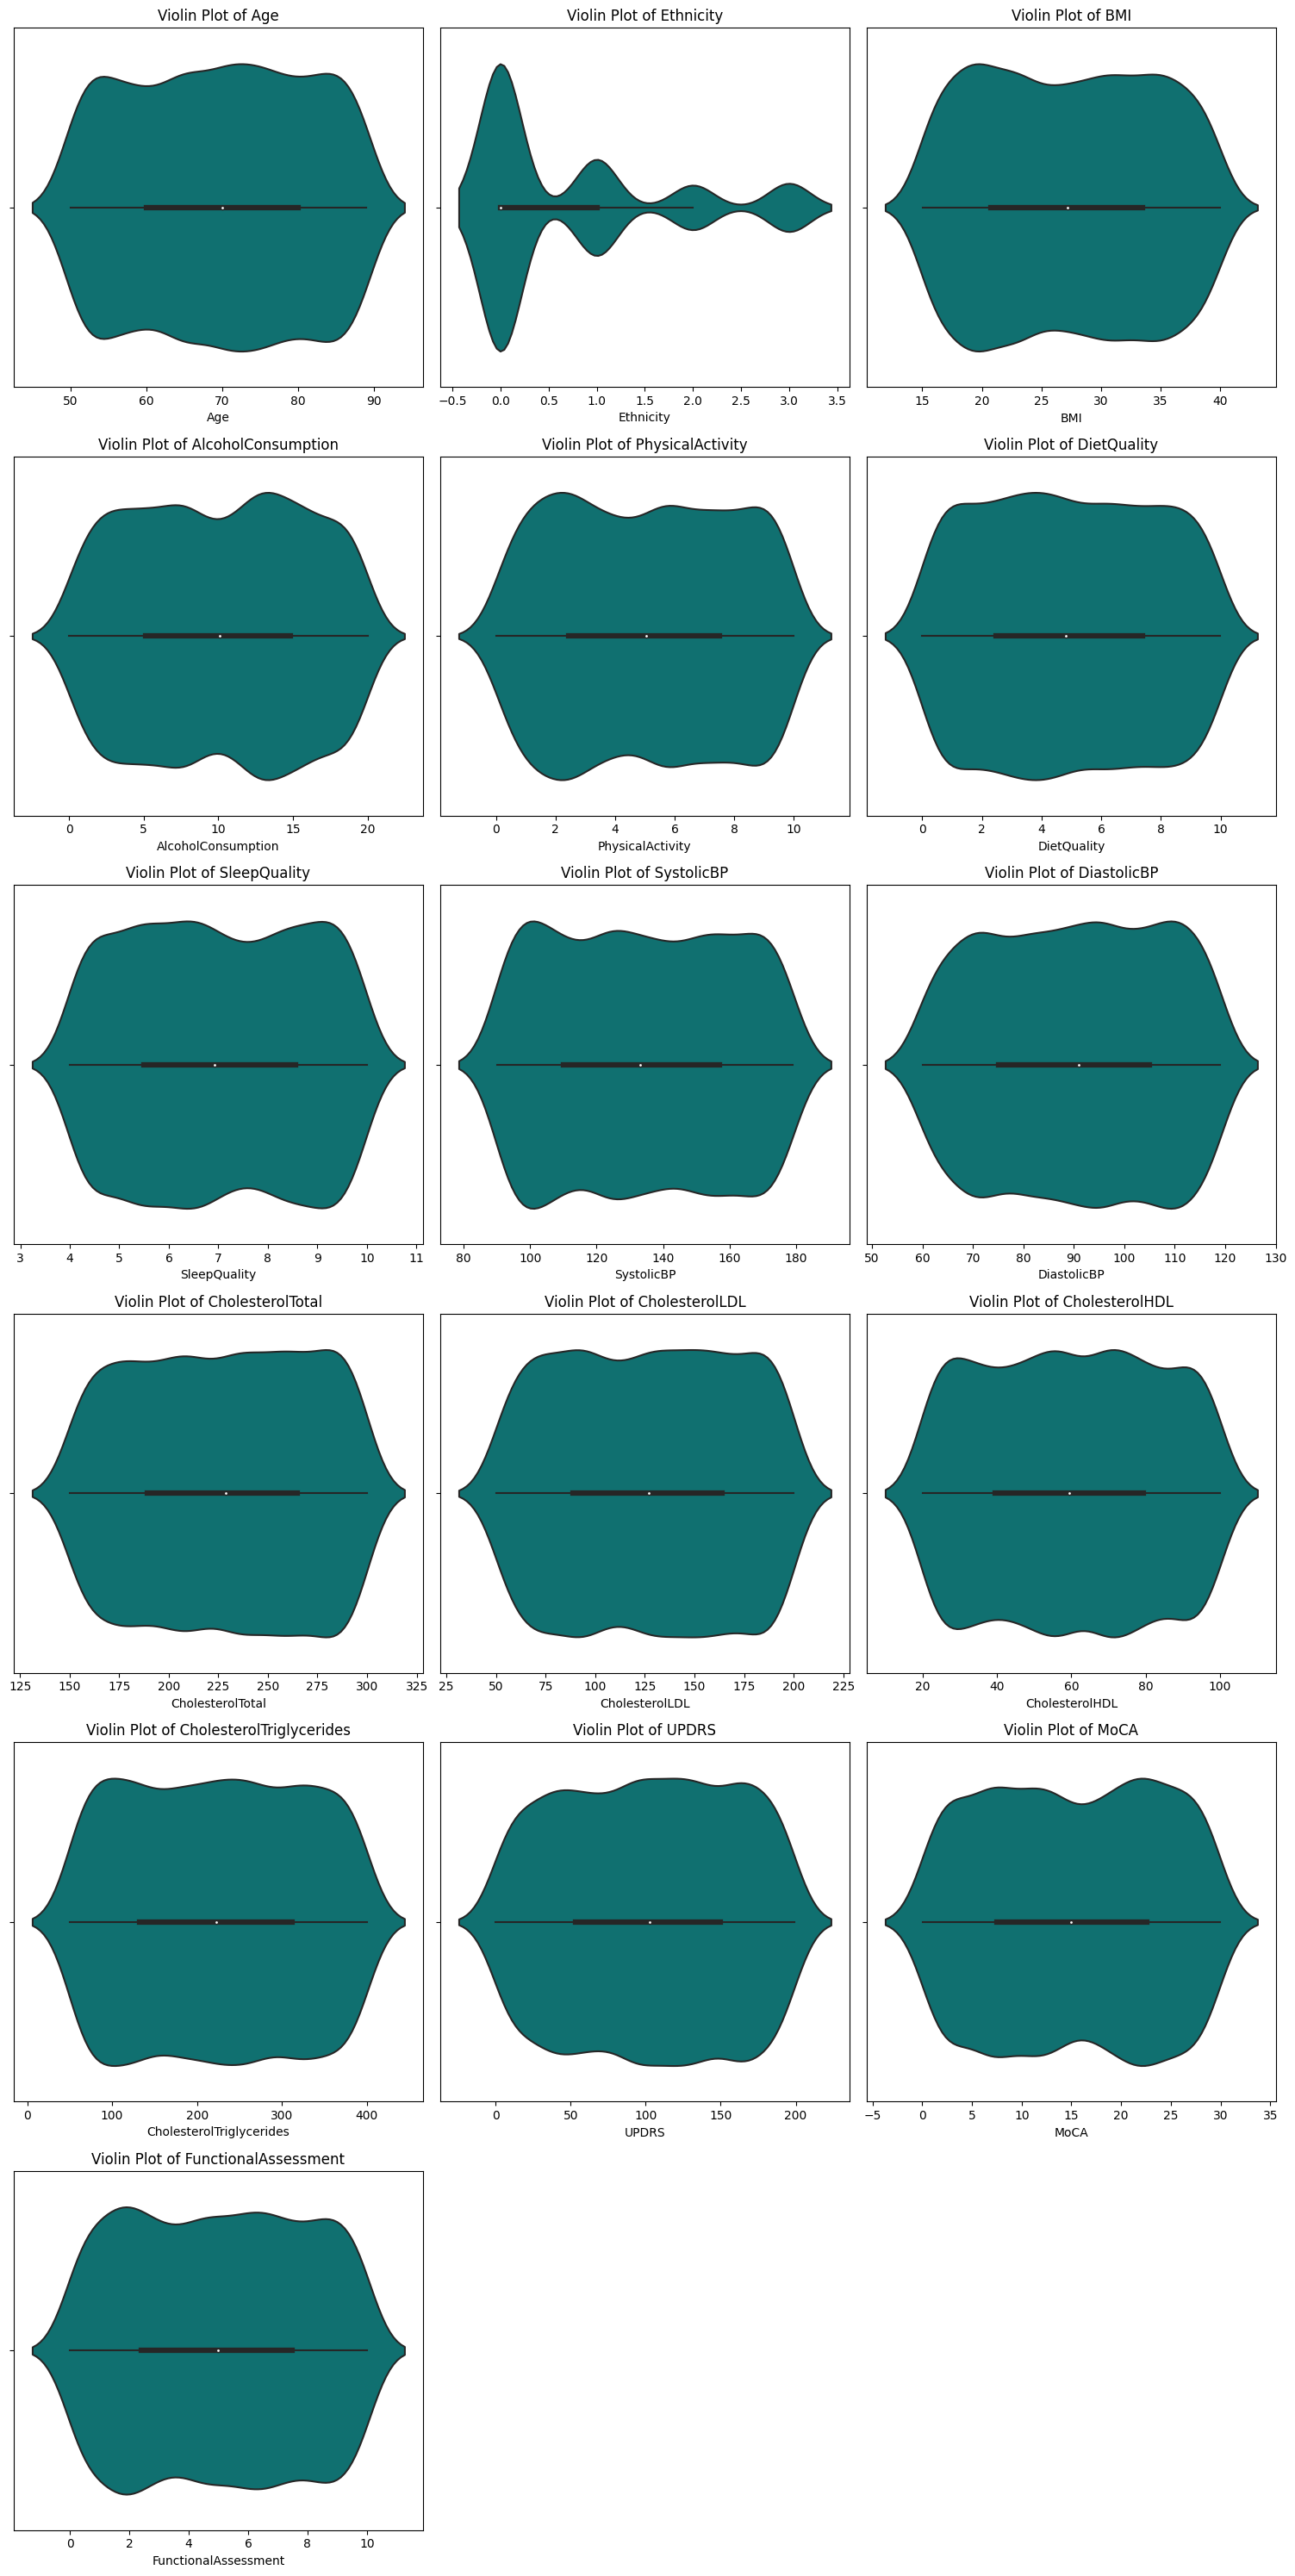

In [192]:
plot_violinplots(df, filtered_classification["numerical"])

In [193]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]
    
        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean

In [194]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from non-binary numerical columns using IQR or Z-score."""
    df_clean = df.copy()
    
    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue
        
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")
    
    return df_clean


In [195]:
from scipy.stats.mstats import winsorize
import numpy as np

def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in non-binary numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()
    
    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue
        
        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])
        
        print(f"🔹 Outliers in '{col}' transformed using {method} method.")
    
    return df_transformed


In [196]:
# Filter out binary columns from the list before passing to transform_outliers
transform_required_columns = ["Stroke"]

# Keep only non-binary numeric columns
valid_transform_columns = [col for col in transform_required_columns 
                           if df[col].nunique() > 2 or not set(df[col].dropna().unique()).issubset({0, 1})]

# Apply transformation only if there's a valid column
if valid_transform_columns:
    df = transform_outliers(df, valid_transform_columns)
else:
    print("⚠️ No valid non-binary columns to transform.")


⚠️ No valid non-binary columns to transform.


In [ ]:
# plot_boxplots(df, filtered_classification["numerical"])

# **6. Correlation Analysis** 

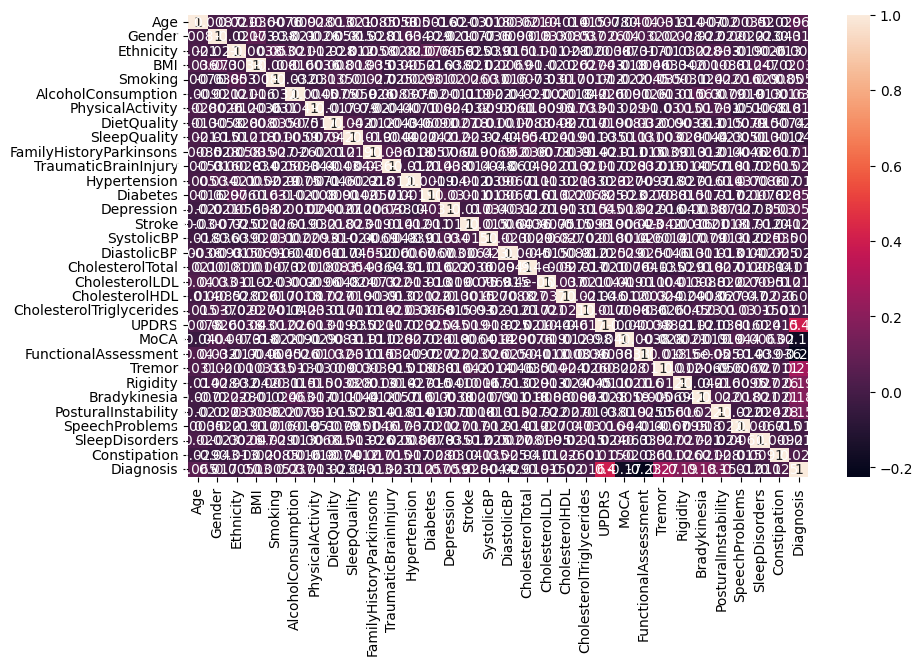

In [197]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [198]:
def plot_correlation_heatmap(df, binary_cols):
    """Plot a heatmap to visualize the correlation between numerical features."""
    plt.figure(figsize=(12, 6))
    correlation_matrix = df[numerical_cols].corr() 
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
    plt.title("🔹 Correlation Heatmap")
    plt.show()

In [199]:
def plot_pairplot(df, binary_cols):
    """Plot pairplot for numerical columns to observe feature relationships."""
    sns.pairplot(df[binary_cols], diag_kind="kde", corner=True)  
    plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

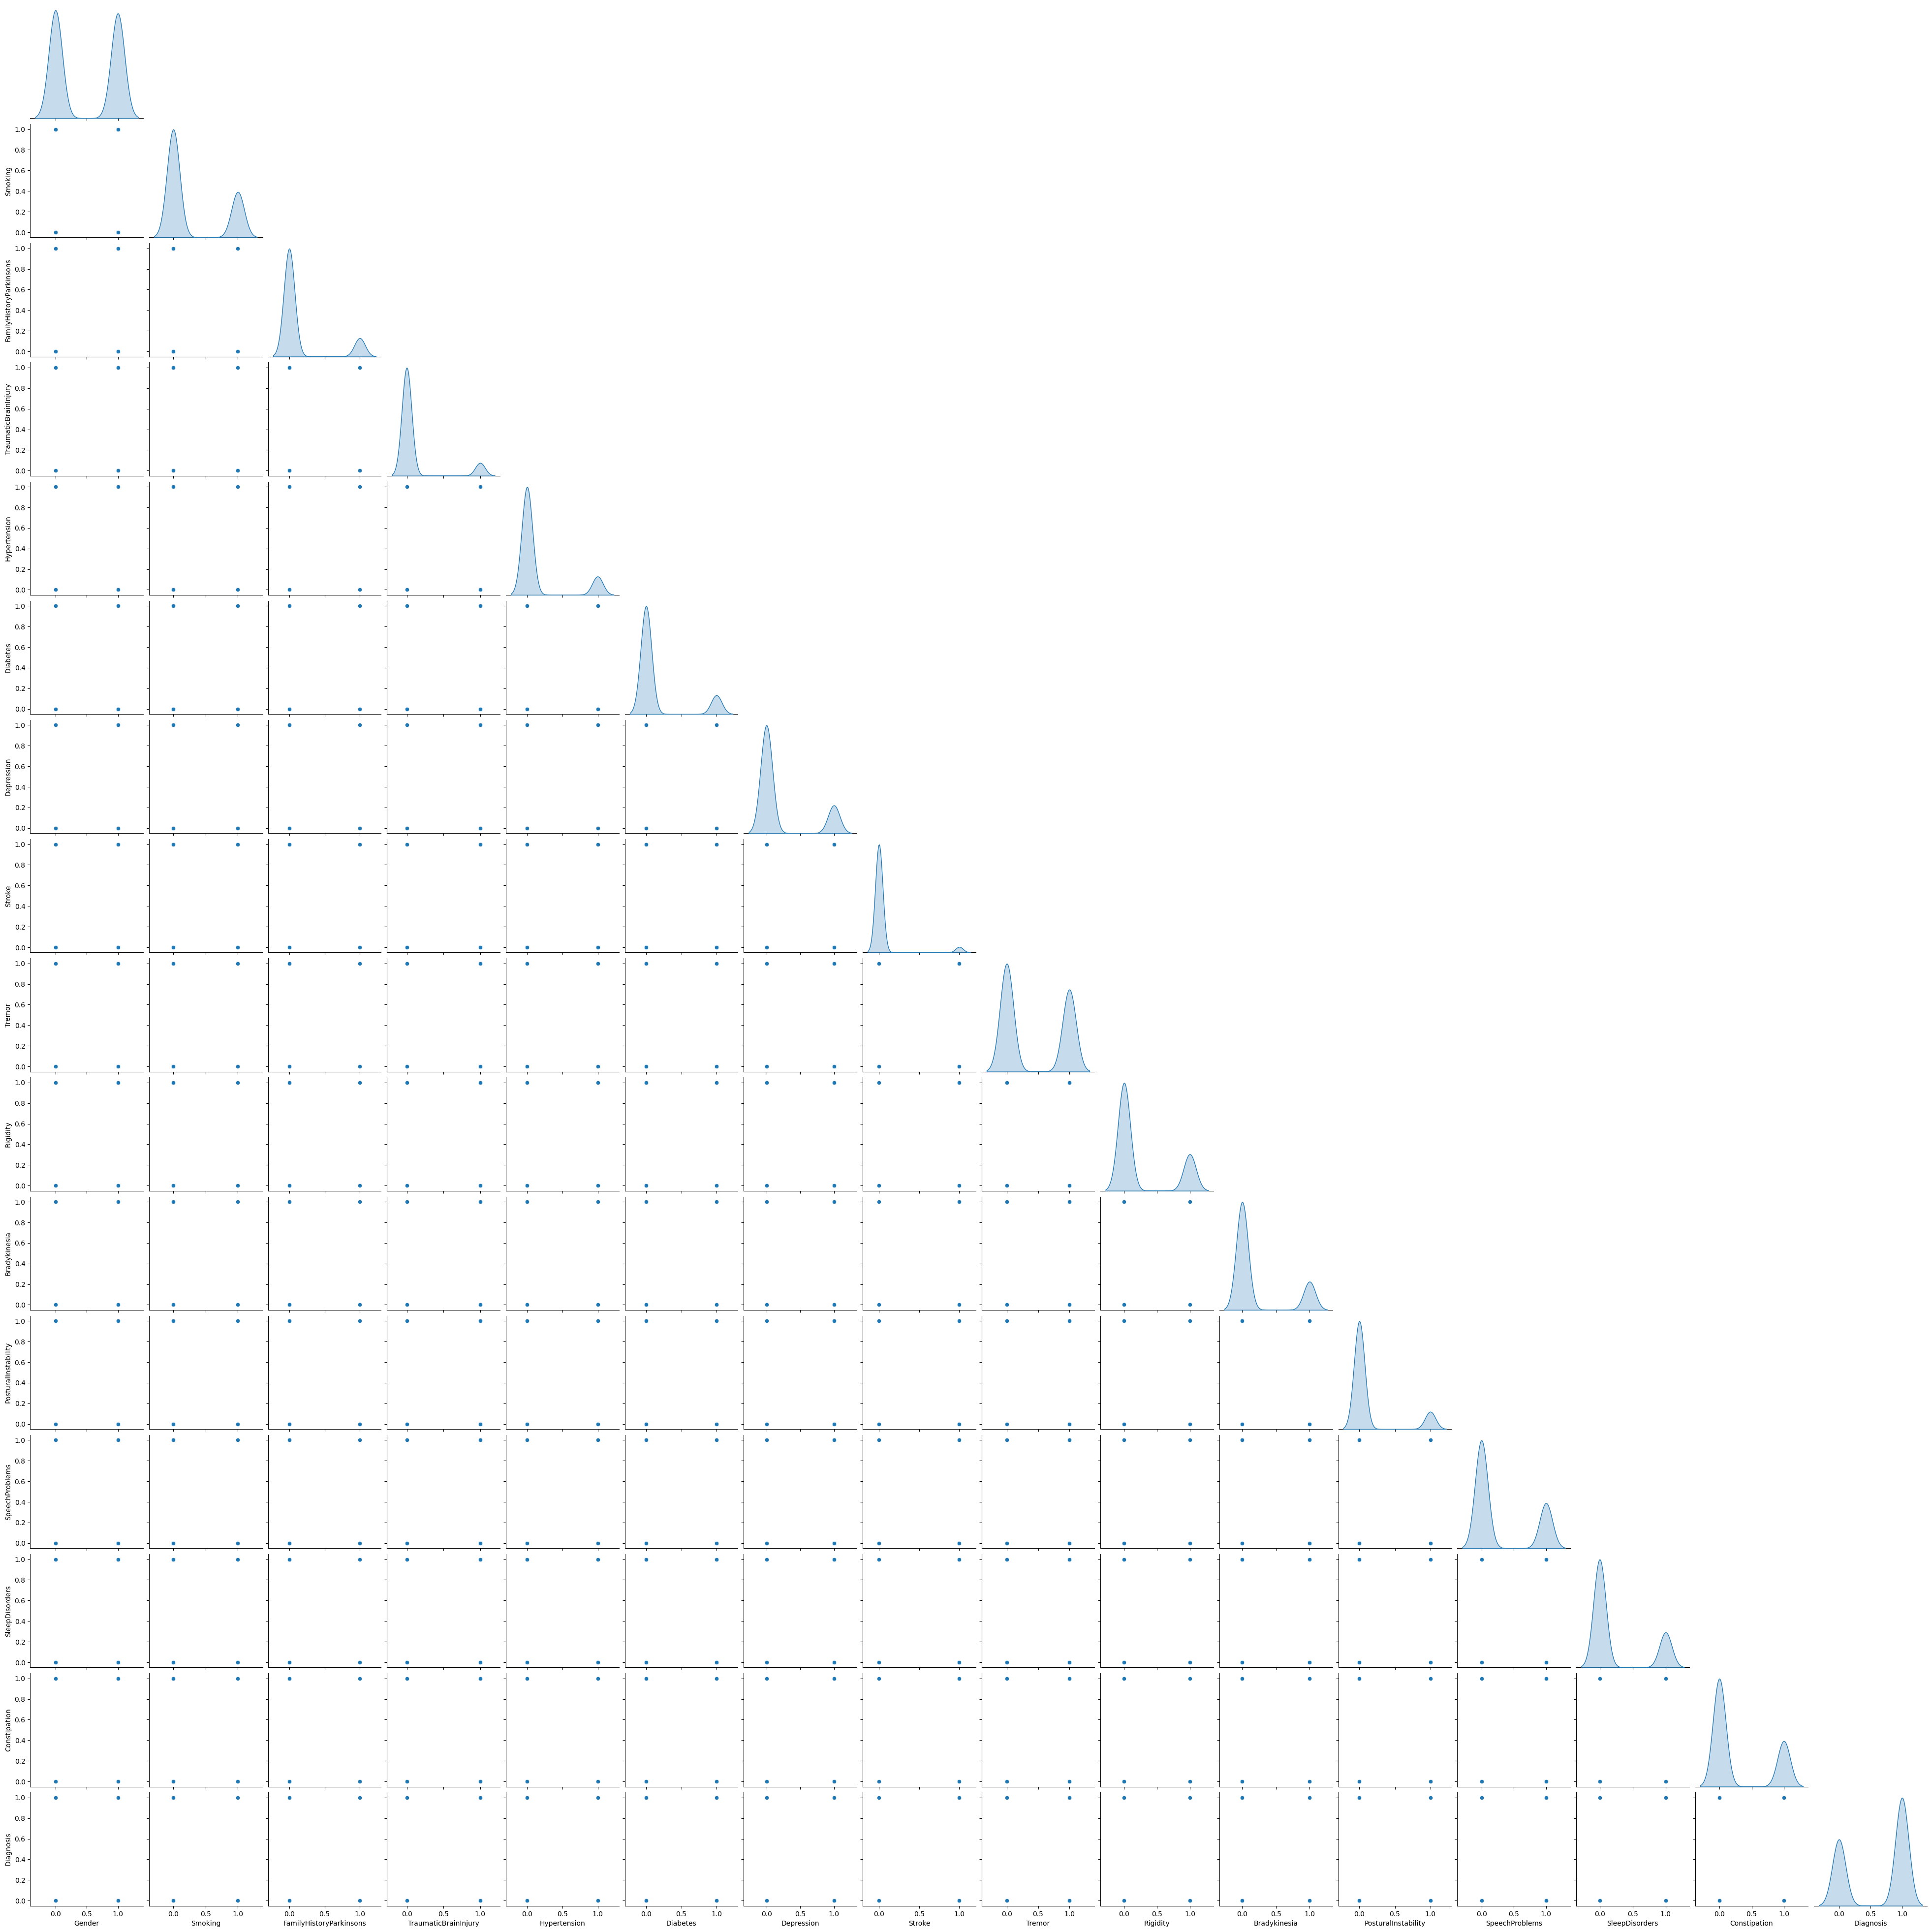

In [200]:
plot_pairplot(df, filtered_classification["binary"])

# 7. Train-Test Split & Sampling Strategy

In [208]:
X = df.drop('Diagnosis',axis=1)
y = df.Diagnosis
X.shape,y.shape

((2105, 31), (2105,))

In [209]:
def train_test_split_custom(df, target_col, test_size=0.2, stratify=True, random_state=42):
    """Function to split data into training and testing sets."""
    X = df.drop('Diagnosis',axis=1)
    y = df.Diagnosis

    if stratify:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)
    else:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    return X_train, X_test, y_train, y_test

In [210]:
X_train, X_test, y_train, y_test = train_test_split_custom(df, "Diagnosis", test_size=0.1)

In [211]:
X_train

,Age,Gender,Ethnicity,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,...,UPDRS,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation
296,51,0,2,35.065330,0,11.453680,6.801010,6.753473,6.061973,1,...,86.693308,3.171572,5.651344,1,1,0,0,0,0,1
1184,59,0,1,15.987603,1,2.854129,0.126635,5.797936,7.714292,0,...,49.523001,21.475758,6.119130,0,0,0,0,1,0,1
348,80,0,0,22.226969,1,17.826902,4.292532,1.992898,5.872701,0,...,198.226612,3.988919,8.771476,1,1,0,0,0,0,0
1453,77,1,1,34.726282,0,0.256870,2.414558,7.026566,6.792079,0,...,41.122402,21.264584,4.157754,1,0,1,0,1,0,0
1815,53,0,0,31.503054,0,14.189784,9.426172,7.275665,4.448940,0,...,42.727806,11.828950,4.131265,0,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
266,81,0,0,29.131808,1,6.949127,0.884417,7.870947,7.729233,1,...,48.234443,16.356330,2.315206,1,0,1,0,0,1,0
1073,61,1,1,17.774334,1,19.852592,0.155256,1.230216,5.501040,0,...,30.486445,11.111033,4.177482,1,0,1,1,0,1,0
595,67,0,0,27.521449,0,0.029186,3.398556,0.622467,6.281534,0,...,190.103947,25.891209,5.814123,0,0,0,0,0,1,1
375,66,1,0,23.187116,0,18.799044,0.977624,9.411928,9.013719,0,...,186.666917,24.422720,7.995728,1,0,0,0,0,1,1


In [212]:
X_test

,Age,Gender,Ethnicity,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,FamilyHistoryParkinsons,...,UPDRS,MoCA,FunctionalAssessment,Tremor,Rigidity,Bradykinesia,PosturalInstability,SpeechProblems,SleepDisorders,Constipation
322,84,1,0,29.951844,0,14.417030,1.373483,7.781587,9.281917,0,...,152.348338,27.645888,0.806785,0,0,0,0,0,0,0
1121,74,1,0,15.244730,0,3.152496,1.915784,2.150938,4.427056,0,...,116.244773,24.267888,0.247179,0,0,1,0,0,0,0
1819,89,0,2,20.441904,0,15.333229,7.726904,8.847785,4.615822,0,...,117.070972,25.795810,4.833723,0,1,0,0,0,0,0
1177,88,1,1,22.593243,0,1.569805,9.656523,0.863681,8.322318,0,...,187.091508,4.179366,2.176483,0,0,0,0,0,1,0
335,70,1,0,36.359094,0,3.633645,6.450680,7.117736,9.333469,0,...,131.961158,4.166588,7.643801,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1080,65,1,0,26.193628,0,6.634742,0.307917,5.214772,6.305687,0,...,100.434131,21.002338,4.613656,0,0,0,0,1,0,1
2028,55,1,1,20.985741,0,0.334326,1.010044,2.889160,8.114024,0,...,12.765964,21.796104,9.760819,1,1,0,0,1,1,0
106,56,0,3,16.472097,1,8.845307,3.754913,3.463191,6.602524,1,...,135.810167,17.923726,9.282444,0,0,0,0,1,0,0
1350,71,1,3,20.522963,0,18.695551,5.487736,3.286817,5.381137,0,...,189.919560,11.803468,5.910132,0,0,1,1,0,0,0


In [213]:
y.value_counts()

Diagnosis
1    1304
0     801
Name: count, dtype: int64

In [214]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Step 2: Data is already split into 80% training and 20% testing
print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

# Step 3: Train Model on Training Set
model = LinearRegression()  # You can replace with any other model
model.fit(X_train, y_train)
print("Model trained successfully")

# Step 4: Predict on Training Set and Calculate Training Error
y_train_pred = model.predict(X_train)

train_mse = mean_squared_error(y_train, y_train_pred)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print("\nTraining Error Metrics:")
print(f"MSE: {train_mse:.4f}")
print(f"MAE: {train_mae:.4f}")
print(f"R²: {train_r2:.4f}")

# Step 5: Predict on Testing Set and Calculate Test Error
y_test_pred = model.predict(X_test)

test_mse = mean_squared_error(y_test, y_test_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("\nTest Error Metrics:")
print(f"MSE: {test_mse:.4f}")
print(f"MAE: {test_mae:.4f}")
print(f"R²: {test_r2:.4f}")

# Step 6: Compare Errors and Diagnose Model Fit
print("\nModel Diagnosis:")
if np.isclose(train_mse, test_mse, rtol=0.1) and np.isclose(train_r2, test_r2, rtol=0.1):
    print("✅ Good Fit: Train Error ≈ Test Error")
elif train_mse < test_mse * 0.7 and train_r2 > test_r2 + 0.1:
    print("⚠️ Overfitting: Train Error Low, Test Error High")
elif train_mse > test_mse * 1.3 and train_r2 < test_r2 - 0.1:
    print("⚠️ Underfitting: Train Error High, Test Error High")
else:
    print("🔍 Moderate Fit: Some difference between train and test errors")

Training set shape: (1894, 31), Test set shape: (211, 31)
Model trained successfully

Training Error Metrics:
MSE: 0.1343
MAE: 0.3100
R²: 0.4302

Test Error Metrics:
MSE: 0.1439
MAE: 0.3213
R²: 0.3889

Model Diagnosis:
🔍 Moderate Fit: Some difference between train and test errors


In [215]:
warnings.filterwarnings("ignore")


# Balancing the target


I will use three techniques:

SMOTE
RandomOverSampler
RandomUnderSampler
✨SMOTE (Synthetic Minority Oversampling Technique): Creates synthetic data points for the minority class based on existing data points in that class. This helps increase the representation of the minority class in the training data.

✨RandomOverSampler: Randomly duplicates data points from the minority class to increase its representation. Unlike SMOTE, it doesn't create synthetic data.

✨RandomUnderSampler: Randomly removes data points from the majority class to reduce its size and match the minority class. This approach can be faster than oversampling techniques.

In [216]:
# pip show scikit-learn
!pip install -U imbalanced-learn==0.10.1

In [217]:
from imblearn.over_sampling import SMOTE,RandomOverSampler
# from imblearn.under_sampling import RandomUnderSampler
# smote = SMOTE()
# X_resampled, y_resampled = smote.fit_resample(X, y)
ros = RandomOverSampler(sampling_strategy='minority')
X_over_resampled, y_over_resampled = ros.fit_resample(X, y)
# rus = RandomUnderSampler(sampling_strategy='majority')
# X_under_resampled, y_under_resampled = rus.fit_resample(X, y)


In [218]:
# print(X_resampled.shape,y_resampled.shape)
# print(X_under_resampled.shape,y_under_resampled.shape)
print(X_over_resampled.shape,y_over_resampled.shape)

(2608, 31) (2608,)


In [219]:
# print(y_resampled.value_counts())
# print(y_under_resampled.value_counts())
print(y_over_resampled.value_counts())

Diagnosis
0    1304
1    1304
Name: count, dtype: int64


In [220]:
pip install xgboost lightgbm catboost imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


RandomOverampler

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                           f1_score, confusion_matrix, mean_absolute_error,
                           mean_squared_error, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                            GradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import RandomOverSampler
import time

# Load your dataset (replace this with your actual data loading)
# df = pd.read_csv('your_dataset.csv')
# X = df.drop('target_column', axis=1)
# y = df['target_column']

# Apply RandomOverSampler to balance the dataset
ros = RandomOverSampler(sampling_strategy='minority', random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)

# Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, 
                                                   test_size=0.2, 
                                                   random_state=42,
                                                   stratify=y_resampled)

def evaluate_model(y_true, y_pred, y_proba=None):
    """Calculate and print all requested metrics"""
    # Classification metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    # Confusion matrix metrics
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    tpr = rec  # True Positive Rate = Recall
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    csi = tp / (tp + fn + fp) if (tp + fn + fp) > 0 else 0  # Critical Success Index
    
    # Error metrics
    if y_proba is not None:
        mae = mean_absolute_error(y_true, y_proba)
        mse = mean_squared_error(y_true, y_proba)
        rmse = np.sqrt(mse)
    else:
        mae = mean_absolute_error(y_true, y_pred)
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
    
    # Print metrics in requested order
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"TPR: {tpr:.4f}")
    print(f"FPR: {fpr:.4f}")
    print(f"CSI: {csi:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    
    if y_proba is not None:
        auc = roc_auc_score(y_true, y_proba)
        print(f"AUC-ROC: {auc:.4f}")
    
    return {
        'accuracy': acc, 'precision': prec, 'recall': rec,
        'f1': f1, 'specificity': specificity, 'tpr': tpr,
        'fpr': fpr, 'csi': csi, 'mae': mae, 'mse': mse,
        'rmse': rmse
    }

def train_logistic_regression(X_train, X_test, y_train, y_test):
    print("\n=== Logistic Regression ===")
    params = {
        'C': [0.001, 0.01, 0.1, 1, 10],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],
        'max_iter': [1000]
    }
    lr = LogisticRegression(random_state=42)
    gs = GridSearchCV(lr, params, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_random_forest(X_train, X_test, y_train, y_test):
    print("\n=== Random Forest ===")
    params = {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5],
        'class_weight': ['balanced']
    }
    rf = RandomForestClassifier(random_state=42, n_jobs=-1)
    gs = GridSearchCV(rf, params, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_svm(X_train, X_test, y_train, y_test):
    print("\n=== SVM ===")
    params = {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto'],
        'probability': [True]
    }
    svm = SVC(random_state=42)
    gs = GridSearchCV(svm, params, cv=3, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_naive_bayes(X_train, X_test, y_train, y_test):
    print("\n=== Naive Bayes ===")
    nb = GaussianNB()
    nb.fit(X_train, y_train)
    
    y_pred = nb.predict(X_test)
    y_proba = nb.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_extra_trees(X_train, X_test, y_train, y_test):
    print("\n=== Extra Trees ===")
    params = {
        'n_estimators': [100, 200],
        'max_depth': [None, 10, 20],
        'class_weight': ['balanced']
    }
    et = ExtraTreesClassifier(random_state=42, n_jobs=-1)
    gs = GridSearchCV(et, params, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_xgboost(X_train, X_test, y_train, y_test):
    print("\n=== XGBoost ===")
    params = {
        'n_estimators': [100, 200],
        'max_depth': [3, 6, 9],
        'learning_rate': [0.01, 0.1],
        'subsample': [0.8, 1.0],
        'scale_pos_weight': [len(y_train[y_train==0])/len(y_train[y_train==1])]
    }
    xgb = XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
    gs = GridSearchCV(xgb, params, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_gradient_boosting(X_train, X_test, y_train, y_test):
    print("\n=== Gradient Boosting ===")
    params = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1],
        'max_depth': [3, 6],
        'subsample': [0.8, 1.0]
    }
    gb = GradientBoostingClassifier(random_state=42)
    gs = GridSearchCV(gb, params, cv=5, scoring='f1')
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_lightgbm(X_train, X_test, y_train, y_test):
    print("\n=== LightGBM ===")
    params = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1],
        'num_leaves': [31, 63],
        'scale_pos_weight': [len(y_train[y_train==0])/len(y_train[y_train==1])]
    }
    lgbm = LGBMClassifier(random_state=42, n_jobs=-1)
    gs = GridSearchCV(lgbm, params, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_catboost(X_train, X_test, y_train, y_test):
    print("\n=== CatBoost ===")
    params = {
        'iterations': [100, 200],
        'learning_rate': [0.01, 0.1],
        'depth': [4, 6],
        'auto_class_weights': ['Balanced']
    }
    cb = CatBoostClassifier(random_state=42, verbose=0)
    gs = GridSearchCV(cb, params, cv=3, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

def train_mlp(X_train, X_test, y_train, y_test):
    print("\n=== MLP (Neural Network) ===")
    params = {
        'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
        'activation': ['relu', 'tanh'],
        'solver': ['adam'],
        'alpha': [0.0001, 0.001],
        'learning_rate': ['constant', 'adaptive'],
        'max_iter': [200, 300],
        'early_stopping': [True]
    }
    mlp = MLPClassifier(random_state=42)
    gs = GridSearchCV(mlp, params, cv=3, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    return evaluate_model(y_test, y_pred, y_proba)

# Main execution
def run_all_models(X_train, X_test, y_train, y_test):
    results = {}
    
    print("Starting model training...\n")
    start_time = time.time()
    
    # Run all models
    results['Logistic Regression'] = train_logistic_regression(X_train, X_test, y_train, y_test)
    # results['Random Forest'] = train_random_forest(X_train, X_test, y_train, y_test)
    # results['SVM'] = train_svm(X_train, X_test, y_train, y_test)
    # results['Naive Bayes'] = train_naive_bayes(X_train, X_test, y_train, y_test)
    # results['Extra Trees'] = train_extra_trees(X_train, X_test, y_train, y_test)
    # results['XGBoost'] = train_xgboost(X_train, X_test, y_train, y_test)
    # results['Gradient Boosting'] = train_gradient_boosting(X_train, X_test, y_train, y_test)
    results['LightGBM'] = train_lightgbm(X_train, X_test, y_train, y_test)
    results['CatBoost'] = train_catboost(X_train, X_test, y_train, y_test)
    results['MLP'] = train_mlp(X_train, X_test, y_train, y_test)
    
    print(f"\nTotal training time: {(time.time()-start_time)/60:.2f} minutes")
    
    return results

# Execute with your data
print("Dataset shape before resampling:", X.shape, y.shape)
print("Class distribution before resampling:", np.bincount(y))

# Apply resampling and split
X_resampled, y_resampled = ros.fit_resample(X, y)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, 
                                                  test_size=0.2, 
                                                  random_state=42,
                                                  stratify=y_resampled)

print("\nDataset shape after resampling:", X_resampled.shape, y_resampled.shape)
print("Class distribution after resampling:", np.bincount(y_resampled))
print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)

model_results = run_all_models(X_train, X_test, y_train, y_test)

Dataset shape before resampling: (2105, 31) (2105,)
Class distribution before resampling: [ 801 1304]

Dataset shape after resampling: (2608, 31) (2608,)
Class distribution after resampling: [1304 1304]
Train shape: (2086, 31) (2086,)
Test shape: (522, 31) (522,)
Starting model training...


=== Logistic Regression ===
Accuracy: 0.8410
Precision: 0.8450
Recall: 0.8352
F1 Score: 0.8401
Specificity: 0.8467
TPR: 0.8352
FPR: 0.1533
CSI: 0.7243
MAE: 0.2395
MSE: 0.1110
RMSE: 0.3332
AUC-ROC: 0.9214

=== LightGBM ===
[LightGBM] [Info] Number of positive: 1043, number of negative: 1043
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001263 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3287
[LightGBM] [Info] Number of data points in the train set: 2086, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Accuracy: 0.9579
Precision: 0.9918
Recall: 0.9234

In [222]:
df.columns.

SyntaxError: invalid syntax (<ipython-input-222-2b173603814f>, line 1)

In [ ]:
!pip install shap lime

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import shap
import lime
from lime import lime_tabular

# Set up feature names
feature_names = ['Age', 'Gender', 'SES', 'Hypertension', 'Heart_Disease', 'BMI',
                'Avg_Glucose', 'Diabetes', 'Smoking_Status']

In [ ]:
def train_logistic_regression(X_train, X_test, y_train, y_test):
    print("\n=== Logistic Regression ===")
    params = {
        'C': [0.001, 0.01, 0.1, 1, 10],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear'],
        'max_iter': [1000]
    }
    lr = LogisticRegression(random_state=42)
    gs = GridSearchCV(lr, params, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    
    y_pred = gs.best_estimator_.predict(X_test)
    y_proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    metrics = evaluate_model(y_test, y_pred, y_proba)
    return metrics, gs.best_estimator_

# Similarly modify all your other training functions (Random Forest, SVM, etc.)
# Change the last line from return evaluate_model(...) to:
# metrics = evaluate_model(y_test, y_pred, y_proba)
# return metrics, gs.best_estimator_

In [ ]:
def run_all_models(X_train, X_test, y_train, y_test):
    results = {}
    models = {}
    
    print("Starting model training...\n")
    start_time = time.time()
    
    # Run all models and store both metrics and models
    results['Logistic Regression'], models['Logistic Regression'] = train_logistic_regression(X_train, X_test, y_train, y_test)
    results['Random Forest'], models['Random Forest'] = train_random_forest(X_train, X_test, y_train, y_test)
    results['SVM'], models['SVM'] = train_svm(X_train, X_test, y_train, y_test)
    results['Naive Bayes'], models['Naive Bayes'] = train_naive_bayes(X_train, X_test, y_train, y_test)
    results['Extra Trees'], models['Extra Trees'] = train_extra_trees(X_train, X_test, y_train, y_test)
    results['XGBoost'], models['XGBoost'] = train_xgboost(X_train, X_test, y_train, y_test)
    results['Gradient Boosting'], models['Gradient Boosting'] = train_gradient_boosting(X_train, X_test, y_train, y_test)
    results['LightGBM'], models['LightGBM'] = train_lightgbm(X_train, X_test, y_train, y_test)
    results['CatBoost'], models['CatBoost'] = train_catboost(X_train, X_test, y_train, y_test)
    results['MLP'], models['MLP'] = train_mlp(X_train, X_test, y_train, y_test)
    
    print(f"\nTotal training time: {(time.time()-start_time)/60:.2f} minutes")
    return results, models

In [ ]:
# Execute with your data
print("Dataset shape before resampling:", X.shape, y.shape)
print("Class distribution before resampling:", np.bincount(y))

# Apply resampling and split
X_resampled, y_resampled = ros.fit_resample(X, y)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, 
                                                  test_size=0.2, 
                                                  random_state=42,
                                                  stratify=y_resampled)

print("\nDataset shape after resampling:", X_resampled.shape, y_resampled.shape)
print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)

# This now returns both metrics and trained models
model_results, trained_models = run_all_models(X_train, X_test, y_train, y_test)

In [ ]:
def perform_xai_analysis(trained_models, X_train, X_test, y_test):
    # Convert to numpy arrays if they're DataFrames
    if hasattr(X_train, 'values'):
        X_train_np = X_train.values
        X_test_np = X_test.values
    else:
        X_train_np = X_train
        X_test_np = X_test
    
    # 1. Feature Importance
    print("\n=== Feature Importance Analysis ===")
    plot_feature_importance(trained_models, X_test_np, y_test)
    
    # Focus on best performing model (Extra Trees)
    best_model_name = 'Extra Trees'
    best_model = trained_models[best_model_name]
    
    # 2. SHAP Analysis
    print(f"\n=== SHAP Analysis for {best_model_name} ===")
    shap_analysis(best_model, X_train_np, X_test_np, best_model_name)
    
    # 3. LIME Explanation
    print(f"\n=== LIME Explanation for {best_model_name} ===")
    lime_explainer(best_model, X_train_np, X_test_np, feature_names, best_model_name)
    
    # 4. Partial Dependence Plots
    print(f"\n=== Partial Dependence Plots for {best_model_name} ===")
    plot_pdp(best_model, X_train_np, feature_names, best_model_name)

# Execute XAI analysis
perform_xai_analysis(trained_models, X_train, X_test, y_test)